# Clasificación automática del orden taxonómico de insectos de trampas Malaise con transfer learning

**Una base para el procesamiento asistido de muestras de biodiversidad neotropical (Estación de Biodiversidad Tiputini)**

Proyecto final · Aprendizaje Supervisado · Maestría en Inteligencia Artificial, USFQ · Miguel Álvarez · noviembre de 2026

**Dónde está cada ítem de la rúbrica**

| # | Ítem de la rúbrica | Puntos | Sección |
|---|---|---|---|
| 8 | Introducción | 0.1 | §1 |
| 4 | EDA | 0.6 | §2 (incluye el análisis de desbalance: población, muestra y familias) |
| 7 | Feature extraction (transfer learning) | 0.25 | §3 |
| 3 | Visualización con t-SNE | 1 | §4 |
| 5 | Pipelines | 0.5 | §5 (`Pipeline` de scikit-learn) |
| 6 | Feature selection tipo filter | 0.25 | §5 (`SelectKBest(f_classif)` dentro del pipeline) |
| 1 | Optimización de hiperparámetros (repeated k-fold, gráficas de la búsqueda, curvas de validación de train y CV para el overfitting, curvas de aprendizaje) | 3.5 | §5 |
| 2 | Comparación estadística de 2 técnicas (10×10, Wilcoxon y t-test) | 3.5 | §6 |
| — | Evaluación final en el test reservado | — | §7 |
| 9 | Conclusiones | 0.1 | §8 |
| 10 | Referencias IEEE y prompts como comentarios en el código | 0.1 | §9 y cada celda de código |
| 11 | Idioma | 0.1 | Todo el notebook |

## §0 · Configuración y datos

El notebook es **portable**. Se ejecutó en un MacBook Pro M3 Pro (aceleración GPU de Apple, MPS), pero corre igual en Google Colab (CUDA o CPU): detecta el dispositivo y, si no encuentra los datos, los descarga de Hugging Face.

- **Datos:** BIOSCAN-1M, paquete de imágenes recortadas a 256 px (`cropped_256.hdf5`, 7.41 GB) y metadatos (`BIOSCAN_Insect_Dataset_metadata.tsv`, 1.23 GB). Licencia CC-BY-3.0.
- **Carpeta de datos:** la variable de entorno `BIOSCAN_DIR` o, por defecto, `~/datasets/BIOSCAN-1M` (en Colab, `/content/BIOSCAN-1M`). **Los datos no van al repositorio.**
- **Muestra guardada:** la primera ejecución copia las imágenes de la muestra a un HDF5 propio (`muestra_N1000_min500_seed42.h5`, unos 150 MB) y guarda los conteos de la población. En las siguientes ejecuciones, o en Colab con solo ese archivo, el notebook funciona en **modo ligero**: no descarga ni lee los 8.6 GB.
- **Registro de la ejecución** (`BIOSCAN_DIR/registro/v1/`): bitácora con fecha y hora (`registro.log`), métricas (`metricas.json`), resultados de cada búsqueda (CSV) y **checkpoints** de cada etapa costosa con `joblib` (búsquedas de hiperparámetros, curva de aprendizaje, validación cruzada 10×10, modelos finales). Si un checkpoint existe y su configuración no cambió, se carga en lugar de recalcularse. Para forzar el recálculo: `RECALCULAR=1`.

In [ ]:
# Instalación: solo lo que falte (en Colab normalmente faltan h5py o huggingface_hub; torch ya viene)
import importlib, subprocess, sys
faltan = [p for p, m in [("h5py", "h5py"), ("huggingface_hub", "huggingface_hub"), ("seaborn", "seaborn")]
          if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
print("Paquetes instalados ahora:", faltan or "ninguno")

Paquetes instalados ahora: ninguno


In [ ]:
# Librerías, semillas, dispositivo y rutas
import os, io, sys, time, json, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import h5py
from PIL import Image
import sklearn, scipy
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, GridSearchCV, cross_validate, learning_curve)
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                       # semilla única de todo el proyecto
N_MIN, N_MAX = 500, 1000        # órdenes con al menos N_MIN imágenes; como máximo N_MAX por orden en la muestra
EN_COLAB = "google.colab" in sys.modules
DATA_DIR = Path(os.environ.get("BIOSCAN_DIR", "/content/BIOSCAN-1M" if EN_COLAB else Path.home() / "datasets" / "BIOSCAN-1M"))
DATA_DIR.mkdir(parents=True, exist_ok=True)
H5_PATH = DATA_DIR / "cropped_256.hdf5"
TSV_PATH = DATA_DIR / "BIOSCAN_Insect_Dataset_metadata.tsv"
MUESTRA_H5 = DATA_DIR / f"muestra_N{N_MAX}_min{N_MIN}_seed{SEED}.h5"      # imágenes de la muestra (~150 MB)
MUESTRA_CSV = MUESTRA_H5.with_suffix(".csv")                              # metadatos de la muestra
POBLACION_JSON = DATA_DIR / "eda_poblacion_bioscan1m.json"                # conteos de los 1.1 M (para el EDA sin el TSV)
MODO_LIGERO = MUESTRA_H5.exists() and MUESTRA_CSV.exists() and POBLACION_JSON.exists()
RUN_DIR = DATA_DIR / "registro" / os.environ.get("RUN_ID", "v1")          # bitácora, métricas y checkpoints de esta ejecución
RUN_DIR.mkdir(parents=True, exist_ok=True)
REUSAR = os.environ.get("RECALCULAR", "0") != "1"                          # RECALCULAR=1 ignora los checkpoints
rng = np.random.default_rng(SEED)

try:
    import torch, torchvision
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
    torch.manual_seed(SEED)
    version_torch = f"torch {torch.__version__} | torchvision {torchvision.__version__}"
except ImportError:                       # permite revisar el resto del notebook sin torch (los embeddings ya guardados se reutilizan)
    torch = None; DEVICE = "sin torch"; version_torch = "torch no instalado"
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")
print(f"Python {platform.python_version()} | {platform.platform()} | CPU: {os.cpu_count()} núcleos")
print(f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | pandas {pd.__version__} | numpy {np.__version__} | {version_torch}")
print(f"Dispositivo para la extracción de features: {DEVICE} | carpeta de datos: {DATA_DIR}")
print(f"Modo ligero (muestra ya guardada, sin los 8.6 GB): {MODO_LIGERO} | registro: {RUN_DIR} | reusar checkpoints: {REUSAR}")

Python 3.12.14 | macOS-27.2.1-arm64-arm-64bit | CPU: 12 núcleos
scikit-learn 1.9.1 | scipy 1.18.1 | pandas 3.1.1 | numpy 2.5.5 | torch 2.15.0 | torchvision 0.29.2
Dispositivo para la extracción de features: mps | carpeta de datos: /Users/miguelestebanalvarez/datasets/BIOSCAN-1M
Modo ligero (muestra ya guardada, sin los 8.6 GB): True | registro: /Users/miguelestebanalvarez/datasets/BIOSCAN-1M/registro/v1 | reusar checkpoints: True


In [ ]:
# Registro de la ejecución: bitácora con fecha y hora, métricas y checkpoints de cada etapa costosa
import logging, hashlib, joblib
from contextlib import contextmanager
log = logging.getLogger("bioscan")
log.handlers.clear(); log.setLevel(logging.INFO); log.propagate = False
fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%Y-%m-%d %H:%M:%S")
for h in (logging.FileHandler(RUN_DIR / "registro.log", encoding="utf-8"), logging.StreamHandler(sys.stdout)):
    h.setFormatter(fmt); log.addHandler(h)
METRICAS = RUN_DIR / "metricas.json"

def registrar_metrica(clave, valor):
    "Agrega o actualiza una métrica en metricas.json (el resumen legible de la ejecución)."
    d = json.loads(METRICAS.read_text()) if METRICAS.exists() else {}
    d[clave] = valor
    METRICAS.write_text(json.dumps(d, indent=2, ensure_ascii=False, default=float))

def huella(config):
    "Identificador corto de una configuración: si cambia cualquier parámetro, cambia el nombre del checkpoint."
    return hashlib.sha1(json.dumps(config, sort_keys=True, default=str).encode()).hexdigest()[:10]

def cacheado(nombre, config, calcular):
    "Carga el checkpoint de una etapa si existe para esa configuración; si no, la calcula y lo guarda."
    ruta = RUN_DIR / f"{nombre}_{huella(config)}.joblib"
    if REUSAR and ruta.exists():
        log.info(f"♻ {nombre}: checkpoint cargado ({ruta.name})")
        return joblib.load(ruta)
    t0 = time.perf_counter()
    obj = calcular()
    joblib.dump(obj, ruta, compress=3)
    log.info(f"✔ {nombre}: calculado en {time.perf_counter() - t0:.0f} s y guardado ({ruta.name}, {ruta.stat().st_size / 1e6:.1f} MB)")
    return obj

entorno = {"python": platform.python_version(), "plataforma": platform.platform(), "sklearn": sklearn.__version__,
           "numpy": np.__version__, "pandas": pd.__version__, "torch": version_torch, "dispositivo": DEVICE,
           "SEED": SEED, "N_MIN": N_MIN, "N_MAX": N_MAX, "modo_ligero": MODO_LIGERO}
(RUN_DIR / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False))
log.info(f"Inicio de la ejecución | {entorno['plataforma']} | {DEVICE} | modo ligero: {MODO_LIGERO}")

2026-11-21 00:27:12 | INFO | Inicio de la ejecución | macOS-27.2.1-arm64-arm-64bit | mps | modo ligero: True


In [ ]:
# Descarga de BIOSCAN-1M desde Hugging Face (solo si los archivos no están; ~8.6 GB, una sola vez)
from huggingface_hub import hf_hub_download
for archivo, destino in ([] if MODO_LIGERO else [("BIOSCAN_Insect_Dataset_metadata.tsv", TSV_PATH), ("cropped_256.hdf5", H5_PATH)]):
    if destino.exists():
        print(f"✔ {archivo} ya está ({destino.stat().st_size / 1e9:.2f} GB)")
    else:
        print(f"Descargando {archivo}…"); t0 = time.perf_counter()
        hf_hub_download(repo_id="bioscan-ml/BIOSCAN-1M", repo_type="dataset", filename=archivo, local_dir=DATA_DIR)
        print(f"✔ {archivo}: {destino.stat().st_size / 1e9:.2f} GB en {time.perf_counter() - t0:.0f} s")
if MODO_LIGERO:
    print(f"Modo ligero: se usa la muestra guardada ({MUESTRA_H5.name}, {MUESTRA_H5.stat().st_size / 1e6:.0f} MB); no hace falta el dataset completo")

Modo ligero: se usa la muestra guardada (muestra_N1000_min500_seed42.h5, 72 MB); no hace falta el dataset completo


In [ ]:
# Inspección de la estructura de los datos ANTES de cargarlos (cómo guarda las imágenes el HDF5 y qué columnas tiene el TSV)
with h5py.File(MUESTRA_H5 if MODO_LIGERO else H5_PATH, "r") as f:
    raiz = list(f.keys())
    print("Claves en la raíz del HDF5:", raiz[:10], f"({len(raiz)} en total)")
    GRUPO = "bioscan_dataset" if "bioscan_dataset" in f else next((k for k in raiz if isinstance(f[k], h5py.Group)), None)
    contenedor = f[GRUPO] if GRUPO else f
    nombres_h5 = list(contenedor.keys())
    ej = contenedor[nombres_h5[0]]
    print(f"Grupo de imágenes: {GRUPO!r} | imágenes: {len(nombres_h5):,} | ejemplo: {nombres_h5[0]!r} → dtype {ej.dtype}, forma {ej.shape}")
cabecera = pd.read_csv(MUESTRA_CSV if MODO_LIGERO else TSV_PATH, sep="," if MODO_LIGERO else "\t", nrows=5)
print("\nColumnas:", list(cabecera.columns))
display(cabecera.drop(columns=[c for c in cabecera.columns if c.lower() == "nucraw"], errors="ignore"))

Claves en la raíz del HDF5: ['bioscan_dataset'] (1 en total)
Grupo de imágenes: 'bioscan_dataset' | imágenes: 10,500 | ejemplo: '3663542.jpg' → dtype uint8, forma (6196,)

Columnas: ['sampleid', 'order', 'family', 'genus', 'species', 'image_file', 'y']


,sampleid,order,family,genus,species,image_file,y
0,BIOUG76683-A12,Diptera,Cecidomyiidae,not_classified,not_classified,BIOUG76683-A12.jpg,0
1,BIOUG76145-G05,Diptera,Dolichopodidae,not_classified,not_classified,BIOUG76145-G05.jpg,0
2,BIOUG67841-E10,Diptera,Chironomidae,not_classified,not_classified,BIOUG67841-E10.jpg,0
3,BIOUG74911-D10,Diptera,Cecidomyiidae,Endaphis,not_classified,BIOUG74911-D10.jpg,0
4,BIOUG76885-E03,Diptera,Cecidomyiidae,not_classified,not_classified,BIOUG76885-E03.jpg,0


In [ ]:
# Lectura de una imagen del HDF5 (guarda los JPEG como bytes; si guardara matrices de píxeles, también se acepta)
def leer_imagen(contenedor, nombre):
    datos = contenedor[nombre][()]
    if isinstance(datos, (bytes, np.bytes_)):
        return Image.open(io.BytesIO(bytes(datos))).convert("RGB")
    arr = np.asarray(datos)
    if arr.ndim == 1:                              # bytes del JPEG guardados como vector uint8
        return Image.open(io.BytesIO(arr.tobytes())).convert("RGB")
    return Image.fromarray(arr.astype(np.uint8)).convert("RGB")

# Fuente de las imágenes: el HDF5 completo hasta que se guarde la muestra; desde entonces, el HDF5 de la muestra (más rápido)
H5_IMG, GRUPO_IMG = (MUESTRA_H5, GRUPO) if MODO_LIGERO else (H5_PATH, GRUPO)

@contextmanager
def abrir_imagenes():
    with h5py.File(H5_IMG, "r") as f:
        yield f[GRUPO_IMG] if GRUPO_IMG else f

with abrir_imagenes() as cont:
    img0 = leer_imagen(cont, nombres_h5[0])
print(f"Imagen de ejemplo: {img0.size[0]}×{img0.size[1]} px, modo {img0.mode}")

Imagen de ejemplo: 276×256 px, modo RGB


## §1 · Introducción

**El problema.** Los inventarios de insectos de una estación de investigación tropical, como la **Estación de Biodiversidad Tiputini** de la USFQ en la Amazonía ecuatoriana, generan miles de ejemplares por muestreo. Las trampas Malaise, un método estándar para insectos voladores, capturan cientos de individuos por semana. El primer paso del procesamiento es separar los ejemplares por **orden** taxonómico (moscas, avispas y hormigas, escarabajos, chinches…). Se hace a mano, con lupa, y consume horas de especialistas que podrían dedicarse a la identificación fina. Un clasificador automático por imagen podría preclasificar las muestras y dejar al experto solo la verificación y los casos dudosos.

**Por qué BIOSCAN-1M.** Todavía no hay un banco de imágenes etiquetadas de insectos de Tiputini. BIOSCAN-1M es el conjunto público más cercano: 1.13 millones de insectos de **trampas Malaise**, fotografiados con microscopio con un protocolo estándar, clasificados por expertos y respaldados por código de barras de ADN. El conjunto completo del proyecto BIOSCAN es en su mayoría **neotropical** (62 % de Costa Rica). Seguimos la recomendación del curso: trabajar con un dataset público similar mientras llegan los datos propios.

**Definición del problema de aprendizaje (T, E, P):**
- **T (tarea):** dada la foto de microscopio de un insecto de trampa Malaise, predecir su **orden**.
- **E (experiencia):** una muestra de BIOSCAN-1M con la etiqueta de orden asignada por expertos.
- **P (desempeño):** **macro-F1**, el promedio del F1 de cada orden. Pesa igual a todos los órdenes. La accuracy sería engañosa: en el dataset completo, el 79 % son Diptera, y un modelo que siempre dijera "Diptera" tendría 79 % de accuracy y sería inútil.

**Preguntas que responde el proyecto:**
1. ¿Basta una red preentrenada en ImageNet (fotos cotidianas), sin reentrenarla, para separar órdenes de insectos de microscopio?
2. Sobre esa misma representación, ¿un clasificador no lineal (**SVM con kernel RBF**) supera a uno lineal (**regresión logística**)? Se responde con una prueba de hipótesis sobre repeated k-fold 10×10.

> **Decisión y por qué:** se clasifica por **orden** y no por especie. El orden es el nivel con el que se separa una muestra de trampa en la práctica, está etiquetado en el 100 % de BIOSCAN (la especie, solo en el 7.5 %) y es transferible: los mismos órdenes existen en Tiputini, aunque las especies sean otras.

## §2 · Análisis exploratorio (EDA) y muestra

2026-11-21 00:27:12 | INFO | Modo ligero: resumen de la población cargado de eda_poblacion_bioscan1m.json


Metadatos: 1,128,313 insectos | imágenes del TSV presentes en el HDF5: 100.0%
Ejemplares (sampleid) repetidos: 0 → una imagen por ejemplar, sin duplicados entre particiones
Proporción etiquetada por rango: {'order': '100.0%', 'family': '98.6%', 'genus': '22.5%', 'species': '7.5%'}


,imágenes,%
Diptera,896324,79.439
Hymenoptera,89311,7.915
Coleoptera,47328,4.195
Hemiptera,46970,4.163
Lepidoptera,32538,2.884
Psocodea,9635,0.854
Thysanoptera,2088,0.185
Trichoptera,1296,0.115
Orthoptera,1057,0.094
Blattodea,824,0.073


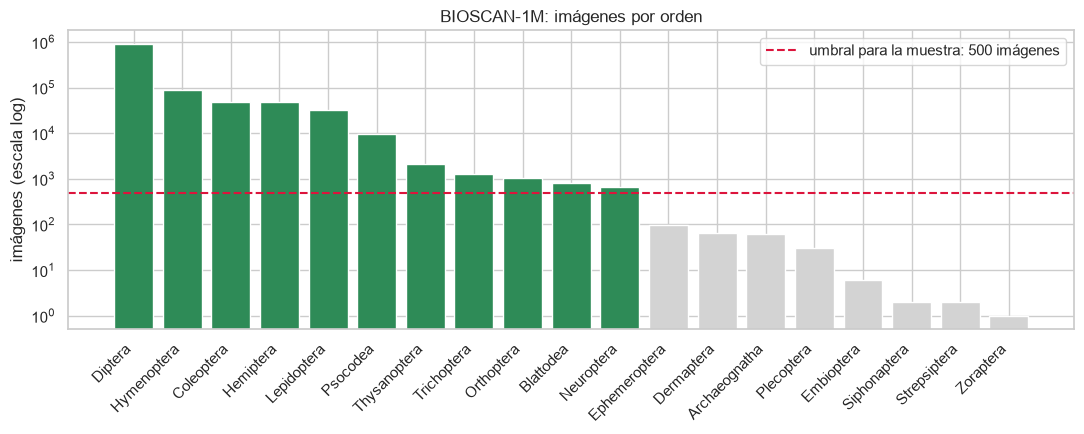

In [ ]:
# Metadatos completos: solo las columnas necesarias (el TSV trae también las secuencias de ADN, que no se usan)
if not MODO_LIGERO:
    cols = {c.lower(): c for c in cabecera.columns}
    usar = [cols[c] for c in ["sampleid", "image_file", "order", "family", "genus", "species"] if c in cols]
    t0 = time.perf_counter()
    meta = pd.read_csv(TSV_PATH, sep="\t", usecols=usar, dtype=str).rename(columns=str.lower)
    dip_all = meta.loc[meta["order"] == "Diptera", "family"]
    dip_all = dip_all[dip_all.notna() & (dip_all != "not_classified")]
    poblacion = {"n_total": len(meta), "en_hdf5": float(meta["image_file"].isin(set(nombres_h5)).mean()),
                 "sampleid_repetidos": int(meta["sampleid"].duplicated().sum()) if "sampleid" in meta else None,
                 "etiquetado": {r: float((meta[r].notna() & (meta[r] != "not_classified")).mean()) for r in ["order", "family", "genus", "species"] if r in meta},
                 "conteo_orden": meta["order"].value_counts().to_dict(),
                 "diptera_familias": dip_all.value_counts().to_dict()}
    POBLACION_JSON.write_text(json.dumps(poblacion, indent=1, ensure_ascii=False))
    log.info(f"Metadatos de la población leídos en {time.perf_counter() - t0:.0f} s y resumidos en {POBLACION_JSON.name}")
else:
    poblacion = json.loads(POBLACION_JSON.read_text())
    log.info(f"Modo ligero: resumen de la población cargado de {POBLACION_JSON.name}")
print(f"Metadatos: {poblacion['n_total']:,} insectos | imágenes del TSV presentes en el HDF5: {poblacion['en_hdf5']:.1%}")
if poblacion["sampleid_repetidos"] is not None:
    print(f"Ejemplares (sampleid) repetidos: {poblacion['sampleid_repetidos']:,} → una imagen por ejemplar, sin duplicados entre particiones")
print("Proporción etiquetada por rango:", {k: f"{v:.1%}" for k, v in poblacion["etiquetado"].items()})

# Tabla: Número de imágenes por orden en BIOSCAN-1M completo (población).
conteo = pd.Series(poblacion["conteo_orden"], name="count").sort_values(ascending=False)
display(conteo.rename("imágenes").to_frame().assign(**{"%": lambda d: (100 * d["imágenes"] / d["imágenes"].sum()).round(3)}))

# Ilustración: Distribución de imágenes por orden en BIOSCAN-1M (escala logarítmica) y umbral mínimo para la muestra.
fig, ax = plt.subplots(figsize=(11, 4.5))
colores = ["seagreen" if n >= N_MIN else "lightgrey" for n in conteo.values]
ax.bar(conteo.index, conteo.values, color=colores); ax.set_yscale("log")
ax.axhline(N_MIN, color="crimson", ls="--", label=f"umbral para la muestra: {N_MIN} imágenes")
ax.set_ylabel("imágenes (escala log)"); ax.set_title("BIOSCAN-1M: imágenes por orden"); ax.legend()
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

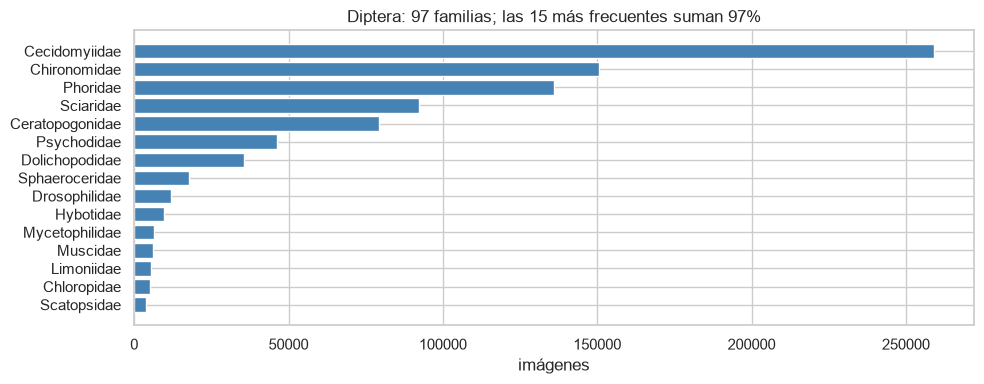

In [ ]:
# Dentro de Diptera (79 % del dataset): las 15 familias más frecuentes, para dimensionar la diversidad interna de la clase mayoritaria
dip = pd.Series(poblacion["diptera_familias"]).sort_values(ascending=False)
# Ilustración: Las 15 familias más frecuentes dentro de Diptera en BIOSCAN-1M.
fig, ax = plt.subplots(figsize=(10, 4))
top = dip.head(15)
ax.barh(top.index[::-1], top.values[::-1], color="steelblue"); ax.set_xlabel("imágenes")
ax.set_title(f"Diptera: {len(dip)} familias; las 15 más frecuentes suman {top.sum() / dip.sum():.0%}")
plt.tight_layout(); plt.show()

In [ ]:
# Muestra de trabajo: órdenes con al menos N_MIN imágenes y como máximo N_MAX por orden, al azar con semilla fija
validos = conteo[conteo >= N_MIN].index.tolist()
excluidos = conteo[conteo < N_MIN]
ORDENES = sorted(validos, key=lambda o: -conteo[o])
if not MODO_LIGERO:
    partes, en_h5 = [], meta["image_file"].isin(set(nombres_h5))
    for o in validos:
        sub = meta[(meta["order"] == o) & en_h5]
        partes.append(sub.sample(n=min(len(sub), N_MAX), random_state=SEED))
    muestra = pd.concat(partes).reset_index(drop=True)
    muestra["y"] = muestra["order"].map({o: i for i, o in enumerate(ORDENES)})
    # Se copian los JPEG de la muestra (tal cual, sin recomprimir) a un HDF5 propio: las siguientes ejecuciones no necesitan los 7.4 GB
    t0 = time.perf_counter()
    with h5py.File(H5_PATH, "r") as fin, h5py.File(MUESTRA_H5, "w") as fout:
        gin = fin[GRUPO] if GRUPO else fin
        gout = fout.create_group(GRUPO or "imagenes")
        for n in muestra["image_file"]:
            gout.create_dataset(n, data=gin[n][()])
    muestra.to_csv(MUESTRA_CSV, index=False)
    log.info(f"Muestra guardada: {MUESTRA_H5.name} ({MUESTRA_H5.stat().st_size / 1e6:.0f} MB) y {MUESTRA_CSV.name} en {time.perf_counter() - t0:.0f} s")
else:
    muestra = pd.read_csv(MUESTRA_CSV, dtype={"image_file": str})
H5_IMG, GRUPO_IMG = MUESTRA_H5, (GRUPO or "imagenes")      # desde aquí, las imágenes se leen de la muestra guardada
print(f"Muestra: {len(muestra):,} imágenes de {len(ORDENES)} órdenes | excluidos ({len(excluidos)}): "
      + ", ".join(f"{o} ({n})" for o, n in excluidos.items()))
# Tabla: Composición de la muestra de trabajo por orden.
display(muestra["order"].value_counts().reindex(ORDENES).rename("imágenes en la muestra").to_frame()
        .assign(**{"en BIOSCAN-1M": conteo.reindex(ORDENES).values}))

Muestra: 10,500 imágenes de 11 órdenes | excluidos (8): Ephemeroptera (96), Dermaptera (66), Archaeognatha (63), Plecoptera (30), Embioptera (6), Siphonaptera (2), Strepsiptera (2), Zoraptera (1)


,imágenes en la muestra,en BIOSCAN-1M
order,,
Diptera,1000,896324
Hymenoptera,1000,89311
Coleoptera,1000,47328
Hemiptera,1000,46970
Lepidoptera,1000,32538
Psocodea,1000,9635
Thysanoptera,1000,2088
Trichoptera,1000,1296
Orthoptera,1000,1057


,clases,imágenes,razón mayor/menor,% de la clase mayor,% de las 4 mayores,equitatividad de Pielou
Población · 19 órdenes,19.0,1128313.0,896324.000,79.439,95.712,0.282
Población · los 11 órdenes de la muestra,11.0,1128047.0,1325.923,79.458,95.735,0.345
Muestra · 11 órdenes,11.0,10500.0,1.479,9.524,38.095,0.997
Población · 97 familias de Diptera,97.0,894161.0,259104.000,28.977,71.332,0.488


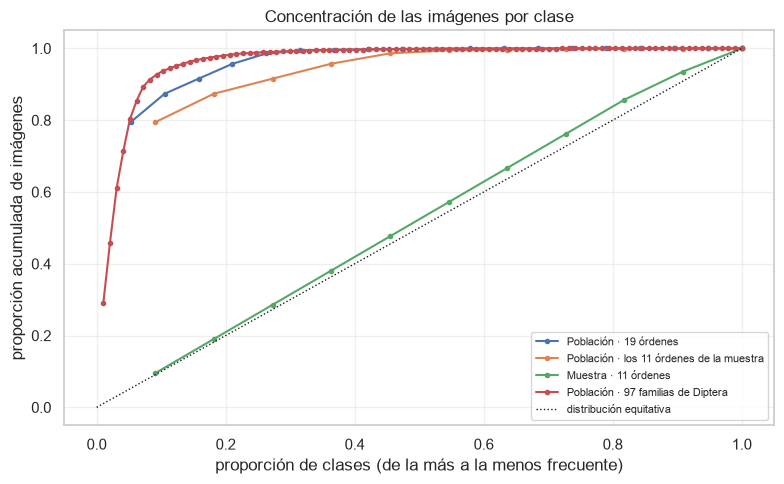

In [ ]:
# Desbalance (1/3): ¿qué tan equitativa es la distribución? Población frente a muestra, con métricas y curvas acumuladas
def pielou(c):
    "Equitatividad de Pielou: índice de Shannon dividido por su máximo, log(número de clases). 1 = todas las clases iguales."
    c = np.asarray(c, dtype=float); c = c[c > 0]; p_ = c / c.sum()
    return float(-(p_ * np.log(p_)).sum() / np.log(len(p_))) if len(p_) > 1 else float("nan")

conjuntos = {"Población · 19 órdenes": conteo, "Población · los 11 órdenes de la muestra": conteo.reindex(ORDENES),
             "Muestra · 11 órdenes": muestra["order"].value_counts().reindex(ORDENES), "Población · 97 familias de Diptera": dip}
# Tabla: Métricas de desbalance de la población, de la muestra y de las familias de Diptera.
desbalance = pd.DataFrame({n: {"clases": len(c), "imágenes": int(c.sum()), "razón mayor/menor": float(c.max() / c.min()),
                               "% de la clase mayor": 100 * c.max() / c.sum(), "% de las 4 mayores": 100 * c.nlargest(4).sum() / c.sum(),
                               "equitatividad de Pielou": pielou(c)} for n, c in conjuntos.items()}).T
display(desbalance.round(3))
registrar_metrica("desbalance", desbalance.round(4).to_dict(orient="index"))

# Ilustración: Proporción acumulada de imágenes frente a la proporción de clases (curva de concentración): órdenes y familias de Diptera.
fig, ax = plt.subplots(figsize=(8, 5))
for n, c in conjuntos.items():
    v = np.sort(np.asarray(c, dtype=float))[::-1]
    ax.plot(np.arange(1, len(v) + 1) / len(v), np.cumsum(v) / v.sum(), "o-", ms=3, label=n)
ax.plot([0, 1], [0, 1], "k:", lw=1, label="distribución equitativa")
ax.set_xlabel("proporción de clases (de la más a la menos frecuente)"); ax.set_ylabel("proporción acumulada de imágenes")
ax.set_title("Concentración de las imágenes por clase"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
# Desbalance (2/3): composición por familia DENTRO de cada orden de la muestra (la muestra es equitativa entre órdenes, no dentro)
fam_m = muestra["family"].fillna("not_classified")
filas = []
for o in ORDENES:
    f = fam_m[muestra["order"] == o]
    vc = f[f != "not_classified"].value_counts()
    filas.append({"orden": o, "imágenes": len(f), "% sin familia": 100 * (f == "not_classified").mean(), "familias": vc.size,
                  "familia principal": vc.index[0] if vc.size else "—", "% familia principal": 100 * vc.iloc[0] / vc.sum() if vc.size else np.nan,
                  "% 3 principales": 100 * vc.head(3).sum() / vc.sum() if vc.size else np.nan, "Pielou (familias)": pielou(vc)})
composicion = pd.DataFrame(filas).set_index("orden")
# Tabla: Composición por familia de cada orden en la muestra: número de familias, familia dominante y equitatividad interna.
display(composicion.round(3))
composicion.to_csv(RUN_DIR / "composicion_familias_muestra.csv")

,imágenes,% sin familia,familias,familia principal,% familia principal,% 3 principales,Pielou (familias)
orden,,,,,,,
Diptera,1000,0.400,36,Cecidomyiidae,27.912,59.337,0.628
Hymenoptera,1000,1.500,35,Scelionidae,19.492,40.914,0.761
Coleoptera,1000,0.500,57,Staphylinidae,19.196,47.638,0.733
Hemiptera,1000,7.200,40,Cicadellidae,40.733,70.474,0.564
Lepidoptera,1000,22.600,43,Gelechiidae,21.059,49.742,0.729
Psocodea,1000,7.400,20,Lepidopsocidae,55.940,79.374,0.534
Thysanoptera,1000,2.900,3,Phlaeothripidae,53.965,100.000,0.741
Trichoptera,1000,0.600,15,Hydroptilidae,58.048,81.590,0.534
Orthoptera,1000,0.700,12,Trigonidiidae,38.771,89.627,0.564


### Desbalance de los datos

**¿Están las imágenes distribuidas de forma equitativa?** No en la población; sí en la muestra entre órdenes; no dentro de cada orden.

| Conjunto | Clases | % de la clase mayor | % de las 4 mayores | Pielou *J* |
|---|---|---|---|---|
| Población · 19 órdenes | 19 | 79.4 | 95.7 | 0.28 |
| Población · los 11 órdenes de la muestra | 11 | 79.5 | 95.7 | 0.35 |
| **Muestra · 11 órdenes** | 11 | **9.5** | **38.1** | **0.997** |
| Población · 97 familias de Diptera | 97 | 29.0 | 71.3 | 0.49 |

*J* = 1 significa que todas las clases pesan igual; 0 significa que todo cae en una sola clase.

1. **La población está muy concentrada (*J* = 0.28).** En la curva de concentración, el 5 % de los órdenes (Diptera) acumula el 80 % de las imágenes.
   - La razón mayor/menor (896 324) no sirve como métrica: la domina Zoraptera, con una sola imagen.
   - Aun quitando los 8 órdenes raros, la razón es de 1 326 a 1 entre Diptera y Neuroptera.
2. **La muestra es casi equitativa entre órdenes (*J* = 0.997).** La curva verde queda pegada a la diagonal: la razón mayor/menor es 1.48 (1 000 frente a 676) y el orden más grande pesa el 9.5 %. Por eso basta con macro-F1 y `class_weight="balanced"`, y no hace falta SMOTE ni sobremuestreo.
3. **El desbalance no desaparece: pasa al interior de cada orden.**
   - **Población:** las 97 familias de Diptera tienen *J* = 0.49. Cecidomyiidae sola es el 29 % y cuatro familias son el 71 %.
   - **Muestra:** la familia dominante pesa entre el 19 % (Coleoptera, Hymenoptera) y el 76 % (Blattodea, Ectobiidae), con *J* interno de 0.41 a 0.76. Diptera aparece con 36 familias, Coleoptera con 57 y Thysanoptera con solo 3.
4. **El etiquetado de familia es incompleto en algunos órdenes:** Lepidoptera tiene un 22.6 % sin familia, y Psocodea y Hemiptera alrededor del 7 %. Esas imágenes no entran al análisis por familia de la §7.

> **Qué implica:**
> - El modelo aprende cada orden sobre todo a partir de sus familias dominantes; las familias raras aportan pocas imágenes. Es una hipótesis comprobable, y la §7 la contrasta ("Errores por familia").
> - La muestra balanceada mide la **capacidad de discriminar** entre órdenes, no el desempeño esperado en una trampa real. Con un 79 % de Diptera, la accuracy en campo la dominaría Diptera, y la precisión de los órdenes raros caería por su baja prevalencia.

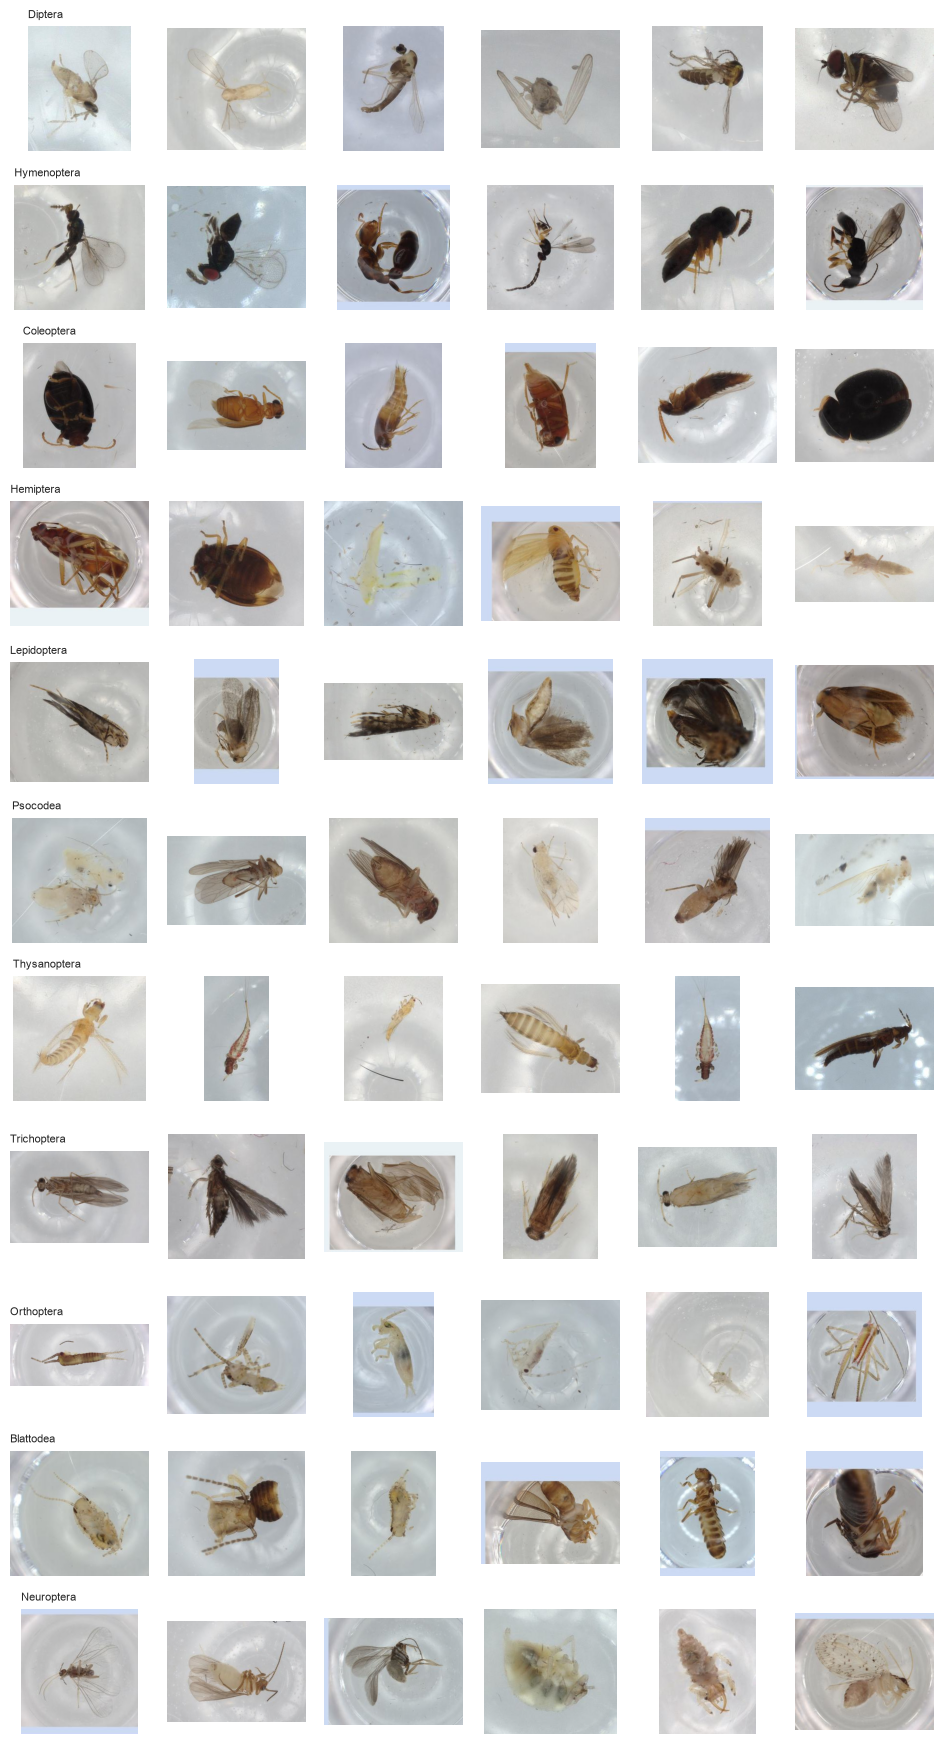

Tamaño de 500 imágenes al azar (px):
       ancho   alto
mean  275.0  256.0
min   120.0  256.0
50%   270.0  256.0
max   549.0  256.0


In [ ]:
# Ejemplos de imágenes por orden y tamaño de las imágenes del paquete recortado
EJ = 6
# Ilustración: Seis ejemplos al azar de cada orden de la muestra (imágenes recortadas a 256 px).
fig, axes = plt.subplots(len(ORDENES), EJ, figsize=(EJ * 1.6, len(ORDENES) * 1.6))
tamanos = []
with abrir_imagenes() as cont:
    for i, o in enumerate(ORDENES):
        nombres = muestra.loc[muestra["order"] == o, "image_file"].sample(EJ, random_state=SEED).tolist()
        for j, n in enumerate(nombres):
            im = leer_imagen(cont, n); axes[i, j].imshow(im); axes[i, j].axis("off")
        axes[i, 0].set_title(o, fontsize=8, loc="left")
    for n in muestra["image_file"].sample(500, random_state=SEED):
        tamanos.append(leer_imagen(cont, n).size)
plt.tight_layout(); plt.show()
tam = pd.DataFrame(tamanos, columns=["ancho", "alto"])
print("Tamaño de 500 imágenes al azar (px):\n", tam.describe().loc[["mean", "min", "50%", "max"]].round(0).to_string())

,casos
imágenes revisadas,10500
no decodificables,0
alto distinto de 256 px,0
ancho atípico (fuera de Q1 − 3·IQR … Q3 + 3·IQR = -73 … 613 px),0
casi uniformes (desv. de grises < 5),1
duplicadas exactas (mismo contenido de píxeles),0


Ancho (px): mín 120, mediana 266, máx 574 | desviación de grises: mín 4.5, p1 9.3, mediana 32.2 | 6 s


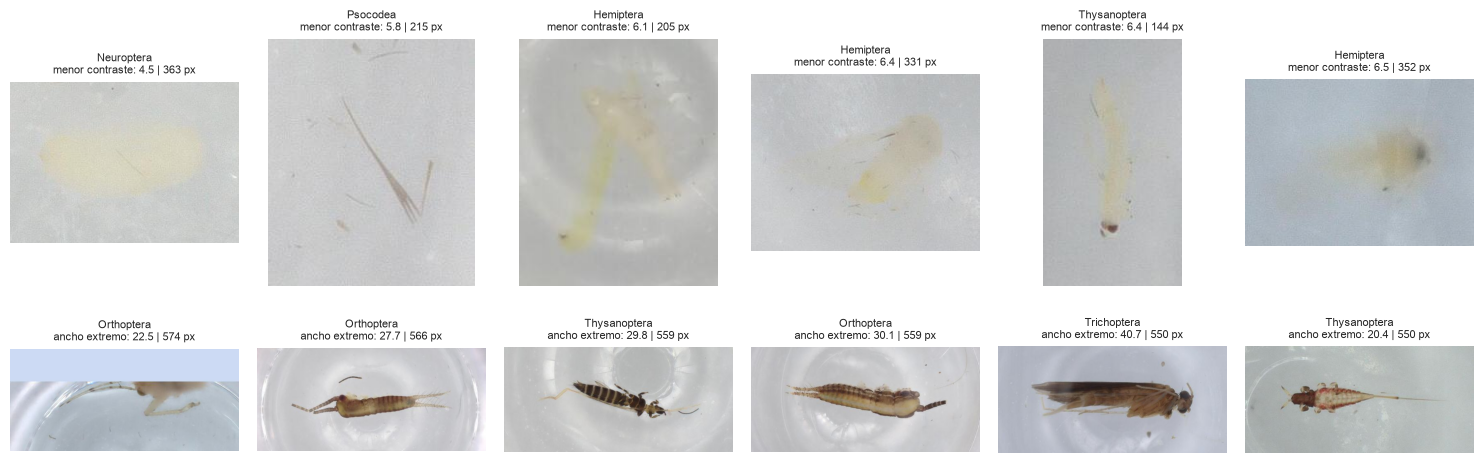

In [ ]:
# Limpieza y control de calidad de las imágenes de la muestra: decodificación, tamaño, contraste y duplicados exactos de contenido
import hashlib
filas, fallas = [], []
t0 = time.perf_counter()
with abrir_imagenes() as cont:
    for n in muestra["image_file"]:
        try:
            img = leer_imagen(cont, n)
            gris = np.asarray(img.convert("L"), dtype=np.float32)
            filas.append({"image_file": n, "ancho": img.size[0], "alto": img.size[1], "media_pixeles": float(gris.mean()),
                          "desv_pixeles": float(gris.std()), "huella": hashlib.md5(np.asarray(img).tobytes()).hexdigest()})
        except Exception as e:                             # imagen corrupta o ausente: se registra, no se descarta en silencio
            fallas.append({"image_file": n, "error": repr(e)[:120]})
calidad = pd.DataFrame(filas).merge(muestra[["image_file", "order"]], on="image_file")
calidad.drop(columns="huella").to_csv(RUN_DIR / "control_calidad_imagenes.csv", index=False)

q1, q3 = calidad["ancho"].quantile([.25, .75]); iqr = q3 - q1
ancho_raro = (calidad["ancho"] < q1 - 3 * iqr) | (calidad["ancho"] > q3 + 3 * iqr)
UMBRAL_CONTRASTE = 5.0                                     # desviación de grises < 5 (de 255) = imagen casi uniforme (vacía o en blanco)
uniforme = calidad["desv_pixeles"] < UMBRAL_CONTRASTE
duplicada = calidad["huella"].duplicated(keep=False)
# Tabla: Control de calidad de las imágenes de la muestra: problemas buscados y número de casos encontrados.
resumen_calidad = pd.Series({
    "imágenes revisadas": len(muestra),
    "no decodificables": len(fallas),
    "alto distinto de 256 px": int((calidad["alto"] != 256).sum()),
    f"ancho atípico (fuera de Q1 − 3·IQR … Q3 + 3·IQR = {q1 - 3 * iqr:.0f} … {q3 + 3 * iqr:.0f} px)": int(ancho_raro.sum()),
    f"casi uniformes (desv. de grises < {UMBRAL_CONTRASTE:g})": int(uniforme.sum()),
    "duplicadas exactas (mismo contenido de píxeles)": int(duplicada.sum()),
}, name="casos").to_frame()
display(resumen_calidad)
print(f"Ancho (px): mín {calidad['ancho'].min()}, mediana {calidad['ancho'].median():.0f}, máx {calidad['ancho'].max()} | "
      f"desviación de grises: mín {calidad['desv_pixeles'].min():.1f}, p1 {calidad['desv_pixeles'].quantile(.01):.1f}, "
      f"mediana {calidad['desv_pixeles'].median():.1f} | {time.perf_counter() - t0:.0f} s")
if fallas:
    display(pd.DataFrame(fallas).head(10))
registrar_metrica("control_calidad", {k: int(v) for k, v in resumen_calidad["casos"].items()})

# Ilustración: Las 6 imágenes de menor contraste y las 6 de ancho más extremo de la muestra, para revisar a ojo si son anomalías.
peores = pd.concat([calidad.nsmallest(6, "desv_pixeles").assign(motivo="menor contraste"),
                    calidad.loc[(calidad["ancho"] - calidad["ancho"].median()).abs().sort_values(ascending=False).index[:6]].assign(motivo="ancho extremo")])
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
with abrir_imagenes() as cont:
    for ax, (_, r) in zip(axes.ravel(), peores.iterrows()):
        ax.imshow(leer_imagen(cont, r["image_file"])); ax.axis("off")
        ax.set_title(f"{r['order']}\n{r['motivo']}: {r['desv_pixeles']:.1f} | {r['ancho']} px", fontsize=8)
plt.tight_layout(); plt.show()

### Limpieza y control de calidad

BIOSCAN-1M llega **curado**: cada ejemplar está recortado de forma automática y su orden lo asignaron expertos con respaldo de ADN. Por eso aquí la limpieza consiste en **verificar** y no en transformar. Estos son todos los controles del notebook:

| Control | Dónde | Resultado | Acción |
|---|---|---|---|
| Orden sin etiqueta | metadatos de la población | 100 % etiquetado | ninguna |
| Ejemplares repetidos (`sampleid`) | metadatos de la población | 0 | ninguna: no puede haber fuga entre desarrollo y test |
| Filas del TSV sin imagen en el HDF5 | muestreo | — | se muestrea solo entre las que tienen imagen |
| Órdenes con menos de 500 imágenes | muestreo | 8 órdenes, 266 imágenes (0.02 %) | se excluyen y se declara como limitación |
| Imágenes que no se pueden abrir | celda anterior | 0 de 10 500 | ninguna |
| Alto distinto de 256 px | celda anterior | 0 | ninguna |
| Ancho atípico (más de 3·IQR) | celda anterior | 0 (rango de 120 a 574 px, mediana 266) | ninguna; el recorte de 224 px se declara como limitación |
| Imágenes casi uniformes (desv. de grises < 5) | celda anterior | 1 | se revisa a ojo: es un ejemplar pálido, no una imagen vacía. Se conserva |
| Duplicados exactos de contenido | celda anterior | 0 | ninguna |
| Familia `not_classified` | análisis por familia | Lepidoptera 22.6 %, Psocodea y Hemiptera ≈ 7 % | se excluyen solo del análisis por familia; para el orden la etiqueta es válida |
| Features constantes de los embeddings | pipeline (`VarianceThreshold`) | 1 (la 1734) | se elimina dentro de cada fold, sin ver los datos de validación |

**Revisión visual de los casos extremos** (ilustración anterior):
- **Menor contraste:** todos son ejemplares reales, pálidos o translúcidos (inmaduros o decolorados en alcohol), sobre el fondo gris del recipiente. El de Psocodea muestra sobre todo apéndices sueltos: parece un ejemplar dañado.
- **Ancho extremo:** son insectos alargados (Orthoptera, Thysanoptera, Trichoptera) bien recortados. La excepción es el Orthoptera de 574 px: el recorte dejó al insecto casi fuera del cuadro y solo se ven las patas.

> **Decisión y por qué:**
> - **No se elimina ninguna imagen.** Los controles automáticos no encuentran fallas. Los 2 casos dudosos (el recorte fallido y el ejemplar dañado) son el 0.02 % de la muestra y no pueden mover el macro-F1.
> - **Ejemplares pálidos, dañados o mal recortados aparecen también en una trampa real.** Quitarlos a mano después de mirarlos sería seleccionar los datos a favor del modelo.
> - **Sin contaminación por el preprocesamiento:** la ResNet-50 queda fuera del `Pipeline` de sklearn, y eso es correcto. Está congelada y normaliza con las medias y desviaciones fijas de ImageNet, no con estadísticas de estos datos, así que no aprende nada del test. Todo lo que sí se ajusta a los datos (escalado, filtro de varianza, selección de features y clasificador) está dentro del `Pipeline` y se reajusta en cada fold.

### Hallazgos del EDA

1. **El desbalance de la población es extremo.** De 1 128 313 imágenes, el **79.4 % son Diptera**. Con Hymenoptera (7.9 %), Coleoptera (4.2 %) y Hemiptera (4.2 %), cuatro órdenes suman el 95.7 %. Ocho órdenes tienen menos de 100 imágenes (Zoraptera, una sola). Un clasificador entrenado con la distribución natural aprendería a decir "Diptera": por eso se muestrea y se mide con macro-F1.
2. **Dentro de Diptera hay mucha diversidad:** decenas de familias (gráfico anterior). La clase mayoritaria no es un grupo homogéneo, lo que anticipa que será de las más difíciles de separar.
3. **El orden está etiquetado en el 100 % de los ejemplares;** la familia, en el 98.6 %; el género, en el 22.5 %; la especie, en el 7.5 %. Confirma que el orden es el nivel viable para un clasificador.
4. **Sin duplicados:** cada ejemplar (`sampleid`) tiene una sola imagen, así que no puede caer el mismo insecto en desarrollo y en test. Es la contaminación típica en imágenes, y aquí no aplica.
5. **La muestra:** 11 órdenes cumplen el mínimo de 500 imágenes → **10 500 imágenes** (9 órdenes con 1 000, Blattodea con 824 y Neuroptera con 676). Los 8 órdenes excluidos suman solo 266 imágenes (0.02 % de la población).
6. **Las imágenes** miden 256 px de alto y entre 120 y 549 px de ancho (mediana 270): el recorte sigue la forma del insecto. El recorte central de 224×224 de la §3 puede cortar los extremos de los insectos alargados (alas, antenas, patas). Es una limitación que se declara.
7. **Licencia:** cada imagen tiene licencia CC BY-NC-SA (CBG Photography Group, Centre for Biodiversity Genomics). Su uso académico es válido con atribución. Las imágenes no se publican en el repositorio.

> **Decisión y por qué (la muestra):**
> - Se trabaja con una **muestra** y no con los 1.1 millones de imágenes, para que el repeated k-fold 10×10 de la §6 (200 entrenamientos) y el t-SNE sean factibles.
> - El **tope por orden** reduce el desbalance extremo (79/1), que haría que el modelo aprendiera "todo es Diptera".
> - El **mínimo de imágenes** garantiza al menos ~40 ejemplos de validación por orden en cada fold.
> - Los **órdenes excluidos** tienen demasiado pocos ejemplos para validarlos: se declara como limitación.
> - La **semilla fija** hace la muestra reproducible.

## §3 · Feature extraction con transfer learning

> **Decisión y por qué:**
> - Se usa **ResNet-50 preentrenada en ImageNet (pesos `IMAGENET1K_V2` de torchvision), congelada**. De cada imagen se toma la salida de la última capa antes del clasificador: un vector de **2 048 features**.
> - **Por qué congelada y no con fine-tuning:** permite un repeated k-fold 10×10 barato y limpio sobre clasificadores clásicos. El fine-tuning exigiría reentrenar la red en cada fold. Además, ResNet-50 es la arquitectura del baseline publicado de BIOSCAN, lo que facilita comparar.
> - **Preprocesamiento:** el que espera la red: recorte central de 224×224 a partir de las imágenes de 256 px y normalización con la media y desviación de ImageNet. **Sin data augmentation**, porque no se entrena la red.
> - **Por qué esto no contamina los datos:** la red no aprende nada de este dataset, sus pesos son fijos. Por eso extraer los embeddings de todas las imágenes antes de dividir no filtra información del test. Todo lo que *sí* aprende de los datos (escalado, selección de features, clasificador) va dentro del `Pipeline` y se ajusta solo con el train de cada fold.

In [ ]:
# Extracción de embeddings (2 048 por imagen) con ResNet-50 congelada; se guardan en disco para no repetirla
EMB_PATH = DATA_DIR / f"embeddings_resnet50_{len(muestra)}_seed{SEED}.npz"
if EMB_PATH.exists():
    z = np.load(EMB_PATH, allow_pickle=True)
    assert list(z["image_file"]) == muestra["image_file"].tolist(), "La muestra cambió: borra el archivo de embeddings y vuelve a extraer"
    X = z["X"]; print(f"Embeddings cargados de {EMB_PATH.name}: {X.shape}")
else:
    from torchvision.models import resnet50, ResNet50_Weights
    from torchvision import transforms
    pesos = ResNet50_Weights.IMAGENET1K_V2
    red = resnet50(weights=pesos); red.fc = torch.nn.Identity(); red.eval().to(DEVICE)
    for p in red.parameters():
        p.requires_grad_(False)                       # congelada: no se entrena
    prep = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                               transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
    LOTE, salida = 64, []
    t0 = time.perf_counter()
    with abrir_imagenes() as cont, torch.no_grad():
        nombres = muestra["image_file"].tolist()
        for i in range(0, len(nombres), LOTE):
            lote = torch.stack([prep(leer_imagen(cont, n)) for n in nombres[i:i + LOTE]]).to(DEVICE)
            salida.append(red(lote).float().cpu().numpy())
            if (i // LOTE) % 20 == 0:
                print(f"  {i + len(lote):,}/{len(nombres):,} imágenes · {time.perf_counter() - t0:.0f} s")
    X = np.concatenate(salida).astype(np.float32)
    np.savez_compressed(EMB_PATH, X=X, image_file=np.array(muestra["image_file"]))
    log.info(f"Embeddings: {X.shape} en {time.perf_counter() - t0:.0f} s en {DEVICE} → guardados en {EMB_PATH.name}")
y = muestra["y"].to_numpy()
print(f"Features por imagen: {X.shape[1]} | valores: media {X.mean():.3f}, desv. {X.std():.3f}, mín {X.min():.3f}, máx {X.max():.3f}")

Embeddings cargados de embeddings_resnet50_10500_seed42.npz: (10500, 2048)
Features por imagen: 2048 | valores: media 0.078, desv. 0.242, mín 0.000, máx 12.804


In [ ]:
# Partición 80 % desarrollo / 20 % test, estratificada por orden. El test se usa una sola vez, en la §7
idx = np.arange(len(y))
idx_dev, idx_test = train_test_split(idx, test_size=0.20, stratify=y, random_state=SEED)
X_dev, y_dev, X_test, y_test = X[idx_dev], y[idx_dev], X[idx_test], y[idx_test]
print(f"Desarrollo: {X_dev.shape} | test: {X_test.shape}")
np.savez(RUN_DIR / "particion.npz", idx_dev=idx_dev, idx_test=idx_test)     # la partición queda registrada
registrar_metrica("muestra", {"imagenes": int(len(y)), "ordenes": ORDENES, "desarrollo": int(len(idx_dev)), "test": int(len(idx_test))})
# Tabla: Imágenes por orden en desarrollo y en test.
display(pd.DataFrame({"desarrollo": np.bincount(y_dev), "test": np.bincount(y_test)}, index=ORDENES))

Desarrollo: (8400, 2048) | test: (2100, 2048)


,desarrollo,test
Diptera,800,200
Hymenoptera,800,200
Coleoptera,800,200
Hemiptera,800,200
Lepidoptera,800,200
Psocodea,800,200
Thysanoptera,800,200
Trichoptera,800,200
Orthoptera,800,200
Blattodea,659,165


## §4 · Visualización del espacio de features con t-SNE

> **Decisión y por qué:**
> - **t-SNE sobre los embeddings del conjunto de desarrollo,** con color = orden real (técnica supervisada).
> - **Antes, PCA a 50 componentes:** es lo recomendado para t-SNE en alta dimensión. Quita ruido y acelera.
> - **Lo que t-SNE no permite interpretar:** conserva vecindades locales, pero ni las distancias entre grupos ni sus tamaños tienen significado.
> - **Por eso se cuantifica aparte:** se mide la separación con la **pureza de vecinos** (qué proporción de los 15 vecinos más cercanos de cada imagen, en el espacio original de 2 048 features, es del mismo orden).

2026-11-21 00:27:19 | INFO | ♻ tsne: checkpoint cargado (tsne_d82ea253a2.joblib)


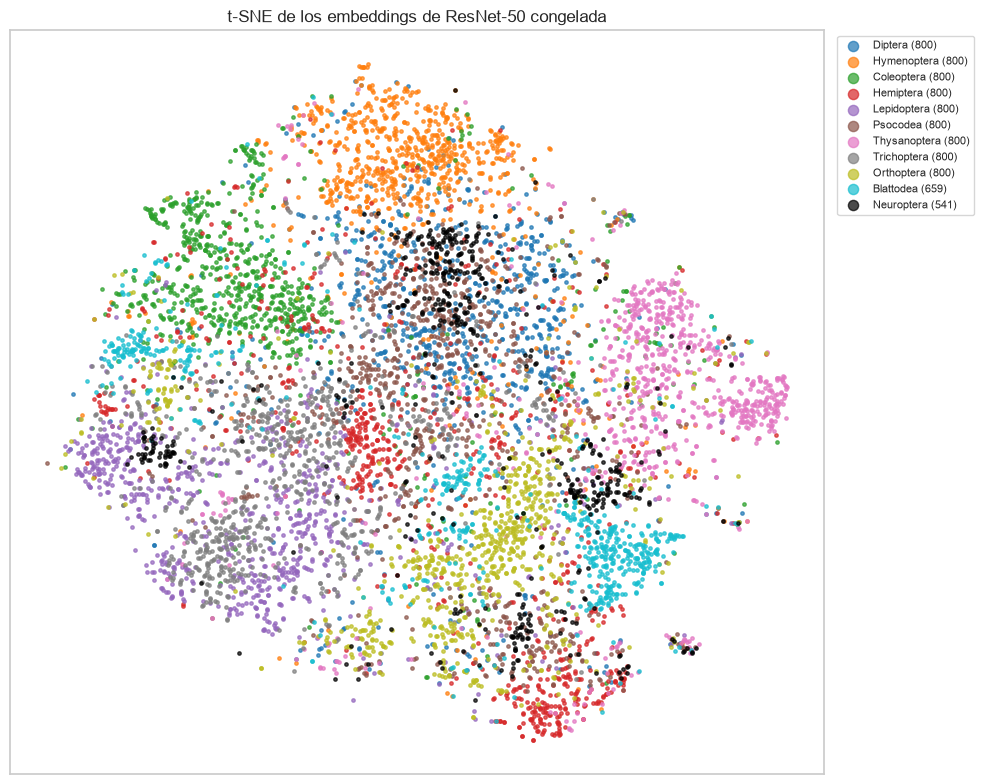

,pureza de vecinos,azar (proporción del orden)
Diptera,0.304,0.095
Hymenoptera,0.434,0.095
Coleoptera,0.496,0.095
Hemiptera,0.298,0.095
Lepidoptera,0.431,0.095
Psocodea,0.468,0.095
Thysanoptera,0.473,0.095
Trichoptera,0.402,0.095
Orthoptera,0.439,0.095
Blattodea,0.540,0.078


Pureza media: 0.430


In [ ]:
# t-SNE (PCA 50 → 2D) de los embeddings de desarrollo, coloreado por orden, y pureza de vecinos en el espacio original
Z = StandardScaler().fit_transform(X_dev)                    # solo para visualizar: no entra en ningún modelo
t0 = time.perf_counter()
emb2 = cacheado("tsne", {"n": len(Z), "perplexity": 30, "pca": 50, "seed": SEED},
                lambda: TSNE(n_components=2, perplexity=30, init="pca", max_iter=1000, random_state=SEED)
                        .fit_transform(PCA(n_components=50, random_state=SEED).fit_transform(Z)))
vec = NearestNeighbors(n_neighbors=16).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
pureza = (y_dev[vec] == y_dev[:, None]).mean(axis=1)

# Ilustración: t-SNE 2D de los embeddings de ResNet-50 (conjunto de desarrollo), coloreado por orden real.
fig, ax = plt.subplots(figsize=(10, 8))
paleta = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#000000"]   # 11 colores distinguibles (tab10 + negro)
for i, o in enumerate(ORDENES):
    m = y_dev == i
    ax.scatter(emb2[m, 0], emb2[m, 1], s=6, color=paleta[i], label=f"{o} ({m.sum()})", alpha=.7)
ax.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("t-SNE de los embeddings de ResNet-50 congelada")
plt.tight_layout(); plt.show()
# Tabla: Pureza de los 15 vecinos más cercanos por orden, en el espacio original de 2 048 features (estandarizado).
display(pd.Series({o: pureza[y_dev == i].mean() for i, o in enumerate(ORDENES)}, name="pureza de vecinos").to_frame()
        .assign(**{"azar (proporción del orden)": [np.mean(y_dev == i) for i in range(len(ORDENES))]}).round(3))
print(f"Pureza media: {pureza.mean():.3f}")
registrar_metrica("tsne_pureza_media", float(pureza.mean()))

### Lectura del t-SNE

**Los embeddings de una red entrenada con fotos cotidianas (ImageNet) ya organizan los insectos por orden, pero sin separarlos del todo.**
- **Grupos bien definidos:** Thysanoptera (trips) forma la región más compacta y aislada; Coleoptera, Hymenoptera, Orthoptera y Blattodea forman regiones propias.
- **Vecinos que anticipan errores:** Lepidoptera y Trichoptera ocupan la misma zona del mapa (abajo a la izquierda). Es la confusión más frecuente en test: entre el 8 % y el 10 % de los Lepidoptera se predicen como Trichoptera (§7). Son órdenes hermanos, con alas cubiertas de escamas o de pelos y una silueta parecida.
- **Grupos mezclados:** **Diptera y Hemiptera** quedan dispersos por el centro del mapa, mezclados con casi todos los demás. Neuroptera aparece en varias islas pequeñas.
- **Pureza de vecinos:** la medición en el espacio original de 2 048 features confirma lo que se ve. De los 15 vecinos más cercanos de una imagen, en promedio el **43 %** es de su mismo orden, frente a ~9 % por azar: **4.5 veces el azar**. Los órdenes más puros son Blattodea (0.54) y Coleoptera (0.50). Los menos puros, **Hemiptera (0.30) y Diptera (0.30)**.
- **Coherencia con la biología:** Diptera es el orden más diverso (decenas de familias de formas muy distintas) y Hemiptera agrupa chinches, cigarras y pulgones, también muy heterogéneos. Ambos son también los órdenes con menor F1 en test (§7): el t-SNE anticipa dónde fallará el clasificador.

**Qué no se puede leer en el gráfico:** que dos grupos estén lejos en el t-SNE no significa que sean más distintos que dos grupos cercanos, y el tamaño de cada nube no indica su variabilidad. t-SNE solo conserva vecindades locales.

## §5 · Pipelines, selección de features y optimización de hiperparámetros

> **Decisión y por qué:**
> - **Pipeline (ítem 5):** `StandardScaler → VarianceThreshold → SelectKBest(f_classif) → clasificador`. Escalado y selección se ajustan **dentro** de cada fold, solo con su parte de entrenamiento: así no hay contaminación.
> - **Feature selection tipo filter (ítem 6), en dos pasos:**
>   - `VarianceThreshold(0)` elimina las features **constantes**. La ResNet termina en una ReLU, así que algunas de las 2 048 salidas valen 0 en todas las imágenes de un fold. En la primera ejecución, la feature 1734 era constante y el estadístico F daba división por cero.
>   - `SelectKBest` con el estadístico F del ANOVA. El número de features `k` es un hiperparámetro más (256, 512, 1 024 o todas).
> - **Las dos técnicas:**
>   - **Regresión logística** multinomial con L2: lineal, rápida, interpretable;
>   - **SVM con kernel RBF:** no lineal, puede trazar fronteras curvas en el espacio de embeddings.
>   - Comparar una lineal con una no lineal responde la pregunta 2 de la introducción.
> - **Validación (ítem 1):** `GridSearchCV` con **`RepeatedStratifiedKFold` (5 folds × 2 repeticiones)** sobre el conjunto de desarrollo, con macro-F1 como métrica de selección. Repetir la partición reduce la varianza de la elección. 5×2 mantiene el costo razonable: la comparación final usa 10×10.
> - **Pesos de clase:** `class_weight="balanced"` en ambos modelos, porque la muestra conserva un desbalance moderado (los órdenes con menos de 1 000 imágenes).

2026-11-21 00:27:21 | INFO | ♻ gridsearch_regresion_logistica: checkpoint cargado (gridsearch_regresion_logistica_ad5295a621.joblib)


Regresión logística: 36 combinaciones × 10 folds
Mejores: {'clf__C': 0.01, 'filtro__k': 1024} | macro-F1 CV = 0.8508 ± 0.0081


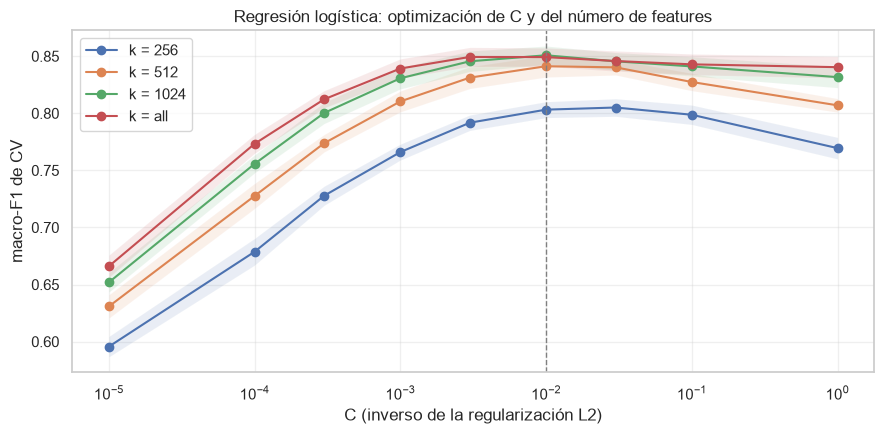

In [ ]:
# Optimización: regresión logística (C × k) con repeated stratified k-fold 5×2 y macro-F1
CV_TUNE = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
pipe_lr = Pipeline([("escala", StandardScaler()), ("varianza", VarianceThreshold(0.0)), ("filtro", SelectKBest(f_classif)),
                    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
grilla_lr = {"filtro__k": [256, 512, 1024, "all"], "clf__C": [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1]}
gs_lr = cacheado("gridsearch_regresion_logistica", {"grilla": grilla_lr, "cv": "5x2", "seed": SEED, "n": len(y_dev), "pipe": str(pipe_lr)},
                 lambda: GridSearchCV(pipe_lr, grilla_lr, cv=CV_TUNE, scoring="f1_macro", n_jobs=-1).fit(X_dev, y_dev))
pd.DataFrame(gs_lr.cv_results_).to_csv(RUN_DIR / "cv_results_regresion_logistica.csv", index=False)
print(f"Regresión logística: {len(gs_lr.cv_results_['params'])} combinaciones × {CV_TUNE.get_n_splits()} folds")
print(f"Mejores: {gs_lr.best_params_} | macro-F1 CV = {gs_lr.best_score_:.4f} ± {gs_lr.cv_results_['std_test_score'][gs_lr.best_index_]:.4f}")

registrar_metrica("regresion_logistica_tuning", {"mejores": gs_lr.best_params_, "macro_f1_cv": float(gs_lr.best_score_),
                  "desv": float(gs_lr.cv_results_["std_test_score"][gs_lr.best_index_])})

def en_borde(busqueda, grilla):
    "Avisa si el mejor valor quedó en el extremo de su grilla ('all' cuenta como el máximo): habría que ampliarla."
    for p, vals in grilla.items():
        v = busqueda.best_params_[p]
        if v in (vals[0], vals[-1]):
            print(f"  ⚠ {p} = {v} está en el borde de la grilla {vals}")
en_borde(gs_lr, grilla_lr)

# Ilustración: Optimización de la regresión logística: macro-F1 de CV (5×2) frente a C, una curva por número de features k.
r = pd.DataFrame(gs_lr.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4.5))
for k in grilla_lr["filtro__k"]:
    d = r[r["param_filtro__k"].astype(str) == str(k)].sort_values("param_clf__C")
    C_ = d["param_clf__C"].astype(float)
    ax.plot(C_, d["mean_test_score"], "o-", label=f"k = {k}")
    ax.fill_between(C_, d["mean_test_score"] - d["std_test_score"], d["mean_test_score"] + d["std_test_score"], alpha=.12)
ax.axvline(gs_lr.best_params_["clf__C"], color="grey", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("C (inverso de la regularización L2)"); ax.set_ylabel("macro-F1 de CV")
ax.set_title("Regresión logística: optimización de C y del número de features"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

2026-11-21 00:27:21 | INFO | ♻ gridsearch_svm_rbf: checkpoint cargado (gridsearch_svm_rbf_72c909aa4b.joblib)


SVM RBF (k = 1024): 15 combinaciones × 10 folds
Mejores: C = 10 | gamma = 9.77e-05 (= 0.1/k) | macro-F1 CV = 0.8533 ± 0.0097


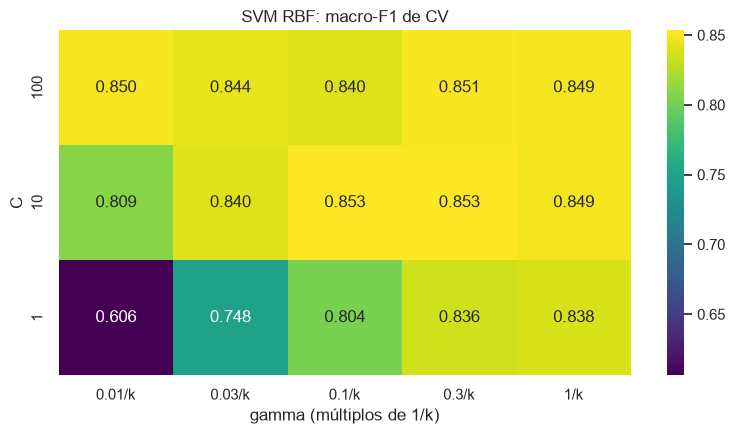

In [ ]:
# Optimización: SVM RBF (C × gamma) con la misma CV; k fijo en el mejor de la regresión logística (para acotar el costo)
k_svm = gs_lr.best_params_["filtro__k"]
pipe_svm = Pipeline([("escala", StandardScaler()), ("varianza", VarianceThreshold(0.0)), ("filtro", SelectKBest(f_classif, k=k_svm)),
                     ("clf", SVC(kernel="rbf", class_weight="balanced", cache_size=2000))])
n_feat = X_dev.shape[1] if k_svm == "all" else k_svm
# Grilla v2: la primera ejecución dejó el óptimo en el borde inferior de gamma (0.1/k) y mostró que C = 0.1 y gamma ≥ 3/k
# eran claramente peores; se amplía gamma hacia abajo y se quitan esas zonas (lección: óptimo en el borde → ampliar)
grilla_svm = {"clf__C": [1, 10, 100], "clf__gamma": [0.01 / n_feat, 0.03 / n_feat, 0.1 / n_feat, 0.3 / n_feat, 1 / n_feat]}
gs_svm = cacheado("gridsearch_svm_rbf", {"grilla": grilla_svm, "cv": "5x2", "seed": SEED, "n": len(y_dev), "pipe": str(pipe_svm)},
                  lambda: GridSearchCV(pipe_svm, grilla_svm, cv=CV_TUNE, scoring="f1_macro", n_jobs=-1).fit(X_dev, y_dev))
pd.DataFrame(gs_svm.cv_results_).to_csv(RUN_DIR / "cv_results_svm_rbf.csv", index=False)
print(f"SVM RBF (k = {k_svm}): {len(gs_svm.cv_results_['params'])} combinaciones × {CV_TUNE.get_n_splits()} folds")
print(f"Mejores: C = {gs_svm.best_params_['clf__C']} | gamma = {gs_svm.best_params_['clf__gamma']:.2e} (= {gs_svm.best_params_['clf__gamma'] * n_feat:g}/k) | "
      f"macro-F1 CV = {gs_svm.best_score_:.4f} ± {gs_svm.cv_results_['std_test_score'][gs_svm.best_index_]:.4f}")
en_borde(gs_svm, grilla_svm)
registrar_metrica("svm_rbf_tuning", {"mejores": {k: float(v) for k, v in gs_svm.best_params_.items()}, "gamma_por_k": float(gs_svm.best_params_["clf__gamma"] * n_feat),
                  "macro_f1_cv": float(gs_svm.best_score_), "desv": float(gs_svm.cv_results_["std_test_score"][gs_svm.best_index_])})

# Ilustración: Optimización del SVM RBF: macro-F1 de CV (5×2) para cada combinación de C y gamma.
r = pd.DataFrame(gs_svm.cv_results_)
tabla = r.pivot(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis", ax=ax,
            xticklabels=[f"{g * n_feat:g}/k" for g in tabla.columns], yticklabels=[f"{c:g}" for c in tabla.index])
ax.set_xlabel("gamma (múltiplos de 1/k)"); ax.set_ylabel("C"); ax.set_title("SVM RBF: macro-F1 de CV")
plt.tight_layout(); plt.show()

2026-11-21 00:27:21 | INFO | ♻ curva_aprendizaje: checkpoint cargado (curva_aprendizaje_2678dd7f72.joblib)


Curva de aprendizaje de SVM RBF


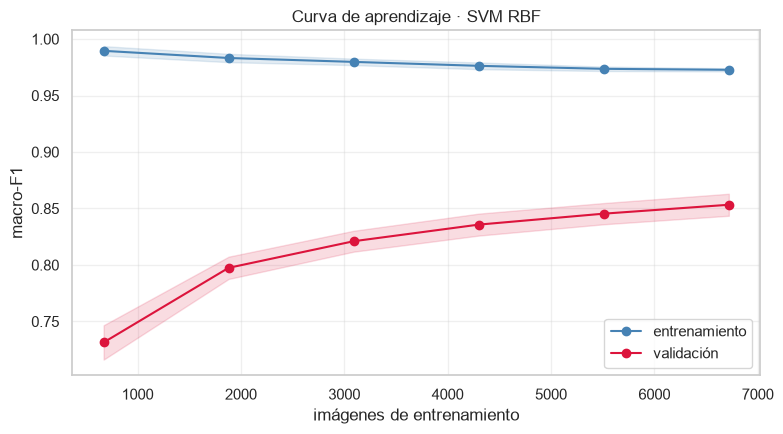

 tamaño  train  validación  brecha
    672 0.9895      0.7314  0.2581
   1881 0.9832      0.7975  0.1857
   3091 0.9798      0.8210  0.1587
   4300 0.9763      0.8357  0.1405
   5510 0.9736      0.8454  0.1282
   6720 0.9727      0.8533  0.1195


In [ ]:
# Curva de aprendizaje del mejor modelo según la CV de optimización (macro-F1 de train y de validación frente al tamaño del train)
mejor_nombre, mejor_busqueda = max([("Regresión logística", gs_lr), ("SVM RBF", gs_svm)], key=lambda t: t[1].best_score_)
tam_tr, sc_tr, sc_va = cacheado("curva_aprendizaje", {"modelo": mejor_nombre, "params": str(mejor_busqueda.best_params_), "seed": SEED, "n": len(y_dev)},
    lambda: learning_curve(mejor_busqueda.best_estimator_, X_dev, y_dev, cv=CV_TUNE, scoring="f1_macro",
                           train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED))
print(f"Curva de aprendizaje de {mejor_nombre}")
# Ilustración: Curva de aprendizaje del mejor modelo: macro-F1 de entrenamiento y de validación (CV 5×2) según el tamaño del train.
fig, ax = plt.subplots(figsize=(8, 4.5))
for s, lab, c in [(sc_tr, "entrenamiento", "steelblue"), (sc_va, "validación", "crimson")]:
    ax.plot(tam_tr, s.mean(1), "o-", color=c, label=lab)
    ax.fill_between(tam_tr, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=.15)
ax.set_xlabel("imágenes de entrenamiento"); ax.set_ylabel("macro-F1"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"Curva de aprendizaje · {mejor_nombre}"); plt.tight_layout(); plt.show()
curva = pd.DataFrame({"tamaño": tam_tr, "train": sc_tr.mean(1), "validación": sc_va.mean(1), "brecha": sc_tr.mean(1) - sc_va.mean(1)})
curva.to_csv(RUN_DIR / "curva_aprendizaje.csv", index=False)
print(curva.round(4).to_string(index=False))

2026-11-21 00:27:21 | INFO | ♻ curva_validacion_rl: checkpoint cargado (curva_validacion_rl_860fd527ee.joblib)


2026-11-21 00:27:21 | INFO | ♻ curva_validacion_svm: checkpoint cargado (curva_validacion_svm_6733f2408f.joblib)


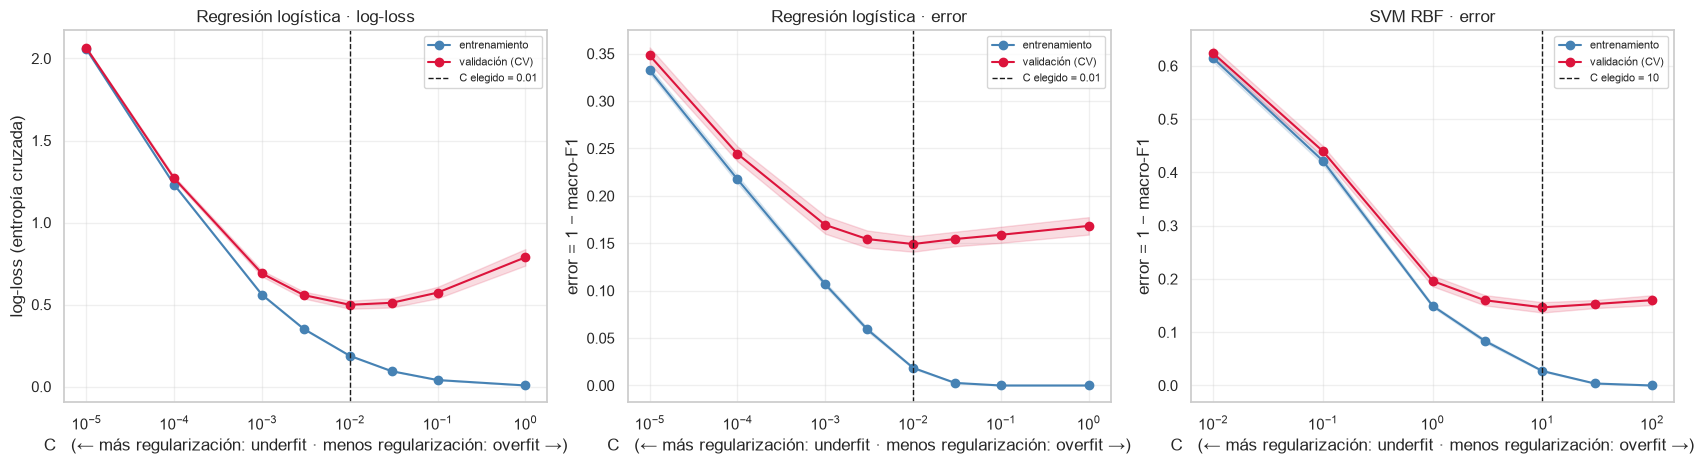

,modelo,C,macro-F1 train,macro-F1 CV,brecha,elegido,log-loss train,log-loss CV
0,Regresión logística,0.0,0.6676,0.6519,0.0157,,2.0565,2.0643
1,Regresión logística,0.0001,0.7825,0.7557,0.0268,,1.2309,1.2699
2,Regresión logística,0.001,0.8933,0.8306,0.0626,,0.5601,0.6896
3,Regresión logística,0.003,0.9407,0.8455,0.0952,,0.3513,0.5577
4,Regresión logística,0.01,0.9814,0.8508,0.1306,◀,0.1878,0.4988
5,Regresión logística,0.03,0.9973,0.8455,0.1518,,0.0941,0.5106
6,Regresión logística,0.1,1.0,0.841,0.159,,0.04,0.5728
7,Regresión logística,1.0,1.0,0.8317,0.1683,,0.007,0.7879
8,SVM RBF,0.01,0.3852,0.376,0.0093,,,
9,SVM RBF,0.1,0.578,0.5599,0.0181,,,


In [ ]:
# Diagnóstico de overfitting (1/2): pérdida de entrenamiento y de validación (CV 5×2) frente a la regularización C de cada modelo
from sklearn.base import clone
def curva_validacion(busqueda, valores, metricas):
    def calcular():
        res = {}
        for v in valores:
            r = cross_validate(clone(busqueda.best_estimator_).set_params(clf__C=v), X_dev, y_dev, cv=CV_TUNE,
                               scoring=metricas, return_train_score=True, n_jobs=-1)
            res[v] = {k: r[k] for k in r if k.startswith(("train_", "test_"))}
        return res
    return calcular

C_RL = [1e-5, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1]
C_SVM = [0.01, 0.1, 1, 3, 10, 30, 100]
vc_rl = cacheado("curva_validacion_rl", {"params": str(gs_lr.best_params_), "C": C_RL, "cv": "5x2", "seed": SEED, "n": len(y_dev)},
                 curva_validacion(gs_lr, C_RL, {"f1": "f1_macro", "logloss": "neg_log_loss"}))
vc_svm = cacheado("curva_validacion_svm", {"params": str(gs_svm.best_params_), "C": C_SVM, "cv": "5x2", "seed": SEED, "n": len(y_dev)},
                  curva_validacion(gs_svm, C_SVM, {"f1": "f1_macro"}))

def serie(vc, clave, signo=1.0, uno_menos=False):
    m = np.array([signo * vc[v][clave].mean() for v in vc]); sd = np.array([vc[v][clave].std() for v in vc])
    return (1 - m if uno_menos else m), sd

# Ilustración: Curvas de validación: pérdida de entrenamiento y de validación (CV 5×2) frente a C; a la izquierda más regularización, a la derecha menos.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
paneles = [(axes[0], vc_rl, "logloss", -1.0, False, "log-loss (entropía cruzada)", "Regresión logística · log-loss", gs_lr.best_params_["clf__C"]),
           (axes[1], vc_rl, "f1", 1.0, True, "error = 1 − macro-F1", "Regresión logística · error", gs_lr.best_params_["clf__C"]),
           (axes[2], vc_svm, "f1", 1.0, True, "error = 1 − macro-F1", "SVM RBF · error", gs_svm.best_params_["clf__C"])]
for ax, vc, clave, signo, um, ylab, titulo, elegido in paneles:
    x = list(vc)
    for parte, lab, col in [("train", "entrenamiento", "steelblue"), ("test", "validación (CV)", "crimson")]:
        m, sd = serie(vc, f"{parte}_{clave}", signo, um)
        ax.plot(x, m, "o-", color=col, label=lab); ax.fill_between(x, m - sd, m + sd, color=col, alpha=.15)
    ax.axvline(elegido, color="k", ls="--", lw=1, label=f"C elegido = {elegido:g}")
    ax.set_xscale("log"); ax.set_xlabel("C   (← más regularización: underfit · menos regularización: overfit →)"); ax.set_ylabel(ylab)
    ax.set_title(titulo); ax.legend(fontsize=8, loc="best"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

filas = []
for nombre, vc, elegido in [("Regresión logística", vc_rl, gs_lr.best_params_["clf__C"]), ("SVM RBF", vc_svm, gs_svm.best_params_["clf__C"])]:
    for v in vc:
        f = {"modelo": nombre, "C": v, "macro-F1 train": vc[v]["train_f1"].mean(), "macro-F1 CV": vc[v]["test_f1"].mean(),
             "brecha": vc[v]["train_f1"].mean() - vc[v]["test_f1"].mean(), "elegido": "◀" if v == elegido else ""}
        if "train_logloss" in vc[v]:
            f.update({"log-loss train": -vc[v]["train_logloss"].mean(), "log-loss CV": -vc[v]["test_logloss"].mean()})
        filas.append(f)
curvas_val = pd.DataFrame(filas)
curvas_val.to_csv(RUN_DIR / "curvas_validacion.csv", index=False)
# Tabla: Macro-F1 y log-loss de entrenamiento y de validación (CV 5×2) para cada valor de C; ◀ marca el valor elegido.
display(curvas_val.round(4).astype(object).fillna(""))
registrar_metrica("overfitting_C_elegido", {n: {"brecha_f1": float(curvas_val.loc[(curvas_val["modelo"] == n) & (curvas_val["elegido"] == "◀"), "brecha"].iloc[0])}
                                            for n in ["Regresión logística", "SVM RBF"]})

2026-11-21 00:27:21 | INFO | ♻ curva_aprendizaje_rl: checkpoint cargado (curva_aprendizaje_rl_47a773306e.joblib)


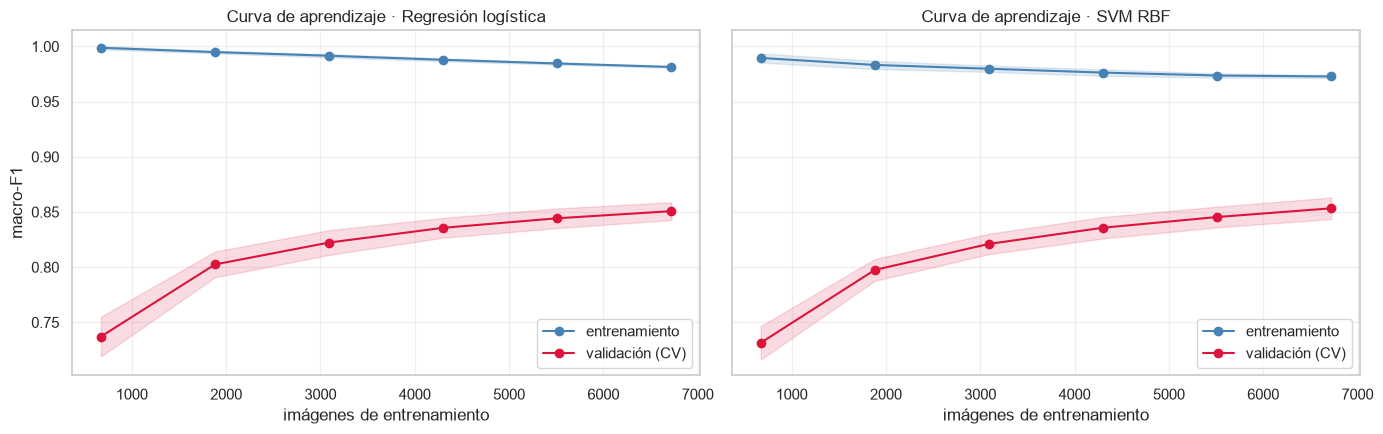

Curva de aprendizaje de la regresión logística
 tamaño  train  validación  brecha
    672 0.9988      0.7371  0.2616
   1881 0.9948      0.8025  0.1924
   3091 0.9915      0.8223  0.1692
   4300 0.9879      0.8356  0.1522
   5510 0.9845      0.8443  0.1402
   6720 0.9814      0.8507  0.1306


In [ ]:
# Diagnóstico de overfitting (2/2): curva de aprendizaje de la regresión logística (el modelo recomendado) junto a la del SVM, con los mismos folds
tam_rl, tr_rl, va_rl = cacheado("curva_aprendizaje_rl", {"params": str(gs_lr.best_params_), "seed": SEED, "n": len(y_dev)},
    lambda: learning_curve(gs_lr.best_estimator_, X_dev, y_dev, cv=CV_TUNE, scoring="f1_macro",
                           train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED))
# Ilustración: Curvas de aprendizaje de los dos modelos: macro-F1 de entrenamiento y de validación (CV 5×2) según el tamaño del train.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (nombre, tt, st, sv) in zip(axes, [("Regresión logística", tam_rl, tr_rl, va_rl), (mejor_nombre, tam_tr, sc_tr, sc_va)]):
    for s_, lab, col in [(st, "entrenamiento", "steelblue"), (sv, "validación (CV)", "crimson")]:
        ax.plot(tt, s_.mean(1), "o-", color=col, label=lab)
        ax.fill_between(tt, s_.mean(1) - s_.std(1), s_.mean(1) + s_.std(1), color=col, alpha=.15)
    ax.set_xlabel("imágenes de entrenamiento"); ax.set_title(f"Curva de aprendizaje · {nombre}"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("macro-F1"); plt.tight_layout(); plt.show()
curva_rl = pd.DataFrame({"tamaño": tam_rl, "train": tr_rl.mean(1), "validación": va_rl.mean(1), "brecha": tr_rl.mean(1) - va_rl.mean(1)})
curva_rl.to_csv(RUN_DIR / "curva_aprendizaje_rl.csv", index=False)
print("Curva de aprendizaje de la regresión logística"); print(curva_rl.round(4).to_string(index=False))

### ¿Hubo overfitting?

**Respuesta corta:** hay una brecha entre entrenamiento y validación (varianza), pero **los modelos elegidos están en el punto de mínima pérdida de validación, no en la zona de overfit**. El test reservado lo confirma.

1. **Las curvas de validación tienen la forma en U de la teoría** (diapositivas *Model Selection* y *Bias variance trade-off*). Como C = 1/λ, el eje está espejado respecto de esas diapositivas:
   - **Regresión logística · log-loss:** la pérdida de entrenamiento baja sin parar, de 2.06 a 0.007. La de validación baja hasta **0.499 en C = 0.01** y vuelve a subir: 0.573 en C = 0.1 y 0.788 en C = 1.
   - **Regresión logística · error (1 − macro-F1):** el mínimo de validación cae en el mismo C = 0.01, con macro-F1 de 0.851. Con C = 1, el entrenamiento llega a 1.000 (memoriza) y la validación cae a 0.832.
   - **SVM RBF · error:** el mínimo de validación está en **C = 10**, con macro-F1 de 0.853. Con C = 100, el entrenamiento llega a 1.000 y la validación baja a 0.840.
   - **El C elegido por `GridSearchCV` coincide en ambos modelos con el mínimo de la curva de validación,** y no está en ningún extremo de la grilla. A la izquierda hay underfit: con C = 10⁻⁵ en la regresión logística o C = 0.01 en el SVM, el entrenamiento y la validación son igual de malos (macro-F1 de validación de 0.65 y 0.38). A la derecha hay overfit.
2. **La brecha en el punto elegido es de 0.13 (regresión logística) y 0.12 (SVM).**
   - Achicarla con más regularización (C menor) también empeora la validación (0.846 en C = 0.003): sería underfit.
   - Es la brecha mínima compatible con el mejor desempeño. Con 2 048 features y 6 720 imágenes de entrenamiento, los datos son casi separables, y por eso el entrenamiento se acerca a 1.
3. **Las curvas de aprendizaje de los dos modelos tienen el mismo diagnóstico: alta varianza.**
   - **Regresión logística:** la brecha baja de 0.26 a 0.13 al pasar de 672 a 6 720 imágenes, y la validación sigue subiendo (0.737 → 0.851) sin estabilizarse.
   - **SVM:** de 0.26 a 0.12, con el mismo patrón.
   - El remedio es **más datos por orden**, no otro modelo ni más regularización.
4. **Confirmación externa: no hay overfitting a la selección de modelo.**
   - El macro-F1 estimado por CV (0.851 la regresión logística, 0.855 el SVM) se reproduce en el test reservado, que nunca se usó para decidir nada (0.851 y 0.861).
   - Si los hiperparámetros se hubieran sobreajustado a la CV, el test habría salido peor.

> **Para la defensa:** "Sí hay varianza: el modelo rinde 0.98 en entrenamiento y 0.85 en validación. Pero elegí la regularización en el mínimo de la pérdida de validación: con menos regularización la validación empeora (overfit) y con más también (underfit). Además, el test reservado coincide con la CV. La curva de aprendizaje indica que más imágenes reducirían esa brecha."

### Resultados de la optimización

**Regresión logística (gráfica de C):**
- **Hiperparámetros elegidos: C = 0.01, k = 1 024 features; macro-F1 de CV = 0.851 ± 0.008.**
- **Forma de la curva:** con mucha regularización (C ≤ 1e-4), el modelo es demasiado simple (macro-F1 de 0.60–0.77, *high bias*). Sube hasta un máximo en C = 0.003–0.01 y luego baja levemente al relajar la regularización (sobreajuste).
- **La selección de features:** con 256 features, el modelo pierde ~5 puntos (0.80). Con 1 024 o con todas, rinde lo mismo (0.851 frente a 0.849). La mitad de las features de la ResNet sobra para este problema: el filtro las descarta sin perder desempeño, con un modelo más pequeño.
- El óptimo no queda en el borde de la grilla.

**SVM RBF (mapa de calor):**
- **Hiperparámetros elegidos: C = 10, gamma = 0.1/k; macro-F1 de CV = 0.853 ± 0.010.**
- **Una meseta amplia:** con C = 10 y gamma entre 0.1/k y 1/k, y con C = 100 en casi todo el rango, el macro-F1 queda entre 0.840 y 0.853. Las diferencias dentro de la meseta son del orden de la desviación entre folds (~0.01). Con gamma muy pequeño (kernel suave, casi lineal), el modelo necesita C grande para rendir: con C = 10 y gamma = 0.01/k cae a 0.81.
- **Zonas pobres:** con C = 1 y gamma muy pequeño, el modelo queda demasiado regularizado y casi lineal: 0.61.
- **La primera grilla dejó gamma en su borde inferior;** se amplió hacia abajo (lección de los labs). Con la grilla v2, **el óptimo quedó en el interior**, y empata con gamma = 0.3/k (0.853).

**Curva de aprendizaje (del SVM, el mejor en la CV de optimización):**
- **Brecha grande:** el F1 de entrenamiento se mantiene en ~0.97–0.99 y el de validación sube de 0.73 (672 imágenes) a 0.853 (6 720). La brecha se reduce de 0.26 a **0.12**, pero sigue siendo grande.
- **Diagnóstico: alta varianza.** El modelo aprende el train casi de memoria, y la validación **todavía sube** al final de la curva.
- **Implicación práctica:** **más imágenes por orden mejorarían el modelo** más que cambiar de clasificador. Es el siguiente paso natural, porque BIOSCAN tiene decenas de miles de imágenes más en los órdenes grandes.

## §6 · Comparación estadística: regresión logística frente a SVM RBF

> **Decisión y por qué:**
> - **Mismos folds para los dos modelos:** `RepeatedStratifiedKFold` 10×10 sobre el conjunto de desarrollo, la misma partición para ambos. Da **100 pares** de macro-F1.
> - **Semilla distinta de la de optimización** (2026 frente a 42): los folds de la comparación no son los mismos que se usaron para elegir los hiperparámetros, lo que atenúa el sesgo de selección.
> - **Hipótesis:** H₀: la mediana (Wilcoxon) o la media (t-test) de la diferencia de macro-F1 entre los modelos es 0. H₁: es distinta de 0. Bilateral, con α = 0.05.
> - **Pruebas:**
>   - **Wilcoxon** de rangos con signo: no supone normalidad;
>   - **t-test pareado:** el que acepta el curso;
>   - **t-test pareado corregido** de Nadeau y Bengio. Los 100 resultados no son independientes, porque los folds comparten el 89 % del entrenamiento, y el t-test simple subestima la varianza. La corrección la infla con el factor (1/J + n_test/n_train).
> - **Tamaño del efecto:** d de Cohen de las diferencias, y cuántas veces gana cada modelo.

2026-11-21 00:27:22 | INFO | ♻ cv10x10_rl: checkpoint cargado (cv10x10_rl_39f100a9b0.joblib)


Regresión logística: 100 entrenamientos | macro-F1 = 0.8506 ± 0.0099
2026-11-21 00:27:22 | INFO | ♻ cv10x10_svm: checkpoint cargado (cv10x10_svm_096b4d1250.joblib)


SVM RBF: 100 entrenamientos | macro-F1 = 0.8548 ± 0.0102


,macro-F1,desv. macro-F1,accuracy,balanced accuracy,segundos por entrenamiento
Regresión logística,0.8506,0.0099,0.8522,0.8512,1.7507
SVM RBF,0.8548,0.0102,0.8563,0.8550,26.4624


,estadístico,p-valor
Wilcoxon de rangos con signo,972.000000,0.000000
t-test pareado,5.783671,0.000000
t-test pareado corregido (Nadeau-Bengio),1.661926,0.099691


Diferencia media (SVM − RL): +0.0042 | IC95 % (t corregido): ±0.0051
d de Cohen de las diferencias: 0.58 | el SVM gana en 77 de 100 folds, pierde en 23, empata en 0


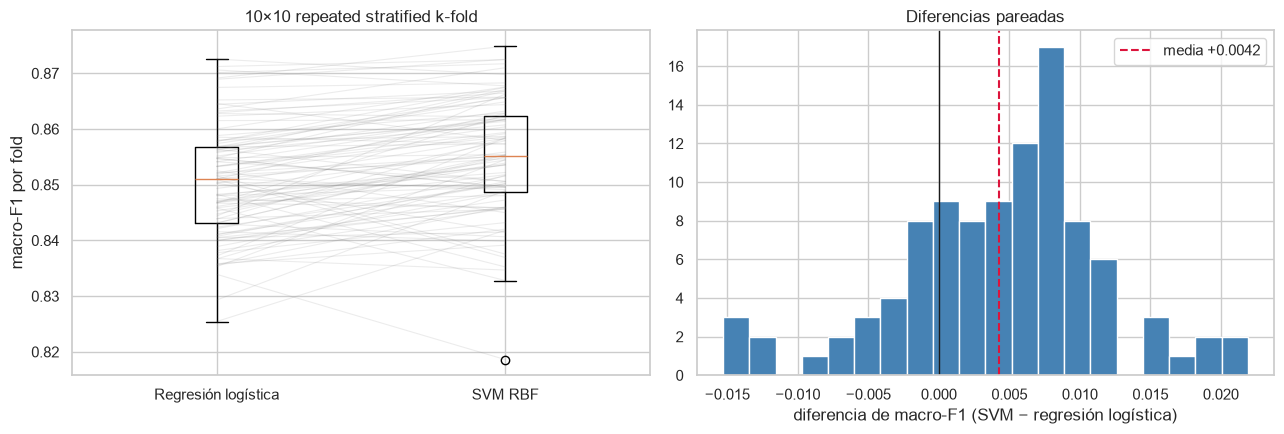

In [ ]:
# Repeated stratified k-fold 10×10 con los mismos folds para ambos modelos (con sus mejores hiperparámetros)
CV_CMP = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=2026)
modelos = {"Regresión logística": gs_lr.best_estimator_, "SVM RBF": gs_svm.best_estimator_}
PARAMS = {"Regresión logística": gs_lr.best_params_, "SVM RBF": gs_svm.best_params_}   # identifican los checkpoints
res_cmp = {}
for nombre, modelo in modelos.items():
    res_cmp[nombre] = cacheado(f"cv10x10_{'rl' if nombre.startswith('Reg') else 'svm'}", {"modelo": nombre, "params": str(PARAMS[nombre]), "cv": "10x10", "seed": 2026, "n": len(y_dev)},
                               lambda: cross_validate(modelo, X_dev, y_dev, cv=CV_CMP, scoring=["f1_macro", "accuracy", "balanced_accuracy"], n_jobs=-1))
    print(f"{nombre}: 100 entrenamientos | macro-F1 = {res_cmp[nombre]['test_f1_macro'].mean():.4f} ± {res_cmp[nombre]['test_f1_macro'].std():.4f}")
pd.DataFrame({f"{n} · {m}": r[f"test_{m}"] for n, r in res_cmp.items() for m in ["f1_macro", "accuracy", "balanced_accuracy"]}).to_csv(RUN_DIR / "comparacion_10x10_por_fold.csv", index_label="fold")

a, b = res_cmp["Regresión logística"]["test_f1_macro"], res_cmp["SVM RBF"]["test_f1_macro"]
d = b - a                                                     # diferencia SVM − regresión logística en cada fold
J = len(d); n_test = len(y_dev) // 10; n_train = len(y_dev) - n_test
t_corr = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=J - 1)
w = stats.wilcoxon(b, a)
tt = stats.ttest_rel(b, a)
# Tabla: Comparación 10×10 (100 folds pareados): métricas medias de cada modelo.
display(pd.DataFrame({n: {"macro-F1": r["test_f1_macro"].mean(), "desv. macro-F1": r["test_f1_macro"].std(),
                          "accuracy": r["test_accuracy"].mean(), "balanced accuracy": r["test_balanced_accuracy"].mean(),
                          "segundos por entrenamiento": r["fit_time"].mean()} for n, r in res_cmp.items()}).T.round(4))
# Tabla: Pruebas de hipótesis sobre las 100 diferencias pareadas de macro-F1 (SVM − regresión logística), α = 0.05.
display(pd.DataFrame({"estadístico": [w.statistic, tt.statistic, t_corr], "p-valor": [w.pvalue, tt.pvalue, p_corr]},
                     index=["Wilcoxon de rangos con signo", "t-test pareado", "t-test pareado corregido (Nadeau-Bengio)"]).round(6))
print(f"Diferencia media (SVM − RL): {d.mean():+.4f} | IC95 % (t corregido): ±{stats.t.ppf(.975, J - 1) * np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1)):.4f}")
print(f"d de Cohen de las diferencias: {d.mean() / d.std(ddof=1):.2f} | el SVM gana en {np.sum(d > 0)} de {J} folds, pierde en {np.sum(d < 0)}, empata en {np.sum(d == 0)}")
registrar_metrica("comparacion_10x10", {"macro_f1_rl": float(a.mean()), "macro_f1_svm": float(b.mean()), "diferencia_media": float(d.mean()),
                  "p_wilcoxon": float(w.pvalue), "p_ttest": float(tt.pvalue), "p_ttest_corregido": float(p_corr), "d_cohen": float(d.mean() / d.std(ddof=1)),
                  "svm_gana": int(np.sum(d > 0)), "rl_gana": int(np.sum(d < 0))})

# Ilustración: Macro-F1 de los dos modelos en los 100 folds pareados (izquierda) y distribución de las diferencias SVM − regresión logística (derecha).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([a, b]); axes[0].set_xticks([1, 2], list(res_cmp)); axes[0].set_ylabel("macro-F1 por fold"); axes[0].set_title("10×10 repeated stratified k-fold")
for x0, x1 in zip(a, b):
    axes[0].plot([1, 2], [x0, x1], color="grey", alpha=.15, lw=.8)
axes[1].hist(d, bins=20, color="steelblue"); axes[1].axvline(0, color="k", lw=1); axes[1].axvline(d.mean(), color="crimson", ls="--", label=f"media {d.mean():+.4f}")
axes[1].set_xlabel("diferencia de macro-F1 (SVM − regresión logística)"); axes[1].legend(); axes[1].set_title("Diferencias pareadas")
plt.tight_layout(); plt.show()

### Resultado de la comparación

| | Regresión logística | SVM RBF |
|---|---|---|
| macro-F1 (10×10, media ± desv.) | 0.8506 ± 0.0099 | 0.8548 ± 0.0102 |
| accuracy / balanced accuracy | 0.852 / 0.851 | 0.856 / 0.855 |
| segundos por entrenamiento | **1.75** | 26.5 (15 veces más) |

**Diferencia media (SVM − RL): +0.0042 de macro-F1.** El SVM gana en 77 de los 100 folds; d de Cohen = 0.58.

| Prueba (H₀: diferencia = 0; α = 0.05) | p-valor | Decisión |
|---|---|---|
| Wilcoxon de rangos con signo | 9.3 × 10⁻⁸ | Rechaza H₀ |
| t-test pareado | 8.6 × 10⁻⁸ | Rechaza H₀ |
| **t-test pareado corregido (Nadeau-Bengio)** | **0.0997** | **No rechaza H₀** |

**Interpretación:**
1. **Las dos primeras pruebas suponen que los 100 resultados son independientes, y no lo son.** En un 10-fold, cada par de conjuntos de entrenamiento comparte el ~89 % de los datos, y las 10 repeticiones reutilizan las mismas imágenes. La varianza real de la diferencia es mucho mayor que la que ven esas pruebas, y sus p-valores son excesivamente optimistas. El t-test corregido infla la varianza con el factor (1/J + n_test/n_train); con él, el p-valor pasa de ~10⁻⁷ a **0.10**.
2. **Conclusión con α = 0.05: no hay evidencia suficiente de que el SVM supere a la regresión logística.** Esto no significa que sean iguales: la diferencia observada es pequeña (+0.4 puntos de macro-F1; IC95 % corregido: [−0.001, +0.009]), y con estos datos no se distingue de cero.
3. **Criterio de elección: "el más simple dentro del empate".** Si los modelos no se distinguen estadísticamente, conviene el más simple. La **regresión logística** entrena 15 veces más rápido, ocupa 0.13 MB frente a 21.8 MB, es lineal (interpretable por coeficientes) y entrega probabilidades directamente. Para un uso real en Tiputini (preclasificar miles de ejemplares en un computador común) esas ventajas pesan más que 0.4 puntos no significativos.

## §7 · Evaluación final en el test reservado

> **Decisión y por qué:** los dos modelos se reentrenan con todo el conjunto de desarrollo y se evalúan **una sola vez** en el 20 % reservado, que no se usó en ningún paso anterior. Además de las métricas, se contrastan en el test con el **test de McNemar exacto**, que solo cuenta las imágenes en que un modelo acierta y el otro falla.

In [ ]:
# Reentrenamiento con todo el desarrollo y evaluación única en test
pred, tiempos = {}, {}
for nombre, modelo in modelos.items():
    def entrenar(modelo=modelo):
        t0 = time.perf_counter(); m = modelo.fit(X_dev, y_dev); return m, time.perf_counter() - t0
    modelo_final, tiempos[nombre] = cacheado(f"modelo_final_{'rl' if nombre.startswith('Reg') else 'svm'}",
                                             {"modelo": nombre, "params": str(PARAMS[nombre]), "n": len(y_dev), "seed": SEED}, entrenar)
    modelos[nombre] = modelo_final                         # checkpoint del modelo final, listo para predecir sin reentrenar
    pred[nombre] = modelo_final.predict(X_test)
pd.DataFrame({"image_file": muestra.loc[idx_test, "image_file"].values, "real": [ORDENES[i] for i in y_test],
              **{f"pred · {n}": [ORDENES[i] for i in p] for n, p in pred.items()}}).to_csv(RUN_DIR / "predicciones_test.csv", index=False)
# Tabla: Métricas de los dos modelos en el test reservado.
display(pd.DataFrame({n: {"macro-F1": f1_score(y_test, p, average="macro"), "accuracy": accuracy_score(y_test, p),
                          "balanced accuracy": balanced_accuracy_score(y_test, p), "segundos de entrenamiento": tiempos[n]}
                      for n, p in pred.items()}).T.round(4))
ok_a, ok_b = pred["Regresión logística"] == y_test, pred["SVM RBF"] == y_test
n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
p_mcnemar = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
print(f"McNemar exacto en test: solo la RL acierta {n01} | solo el SVM acierta {n10} | p = {p_mcnemar:.4f}")
registrar_metrica("test", {**{n: {"macro_f1": float(f1_score(y_test, p, average="macro")), "accuracy": float(accuracy_score(y_test, p)),
                                  "balanced_accuracy": float(balanced_accuracy_score(y_test, p))} for n, p in pred.items()},
                           "mcnemar": {"solo_rl": n01, "solo_svm": n10, "p": float(p_mcnemar)}})
for nombre, p in pred.items():
    print(f"\n{nombre}\n" + classification_report(y_test, p, target_names=ORDENES, digits=3, zero_division=0))

2026-11-21 00:27:22 | INFO | ♻ modelo_final_rl: checkpoint cargado (modelo_final_rl_353db41ee1.joblib)


2026-11-21 00:27:22 | INFO | ♻ modelo_final_svm: checkpoint cargado (modelo_final_svm_2678dd7f72.joblib)


,macro-F1,accuracy,balanced accuracy,segundos de entrenamiento
Regresión logística,0.8514,0.8538,0.8529,0.5177
SVM RBF,0.8610,0.8633,0.8628,4.4838


McNemar exacto en test: solo la RL acierta 51 | solo el SVM acierta 71 | p = 0.0850

Regresión logística
              precision    recall  f1-score   support

     Diptera      0.804     0.820     0.812       200
 Hymenoptera      0.905     0.905     0.905       200
  Coleoptera      0.894     0.885     0.889       200
   Hemiptera      0.828     0.770     0.798       200
 Lepidoptera      0.902     0.830     0.865       200
    Psocodea      0.834     0.805     0.819       200
Thysanoptera      0.885     0.925     0.905       200
 Trichoptera      0.837     0.875     0.856       200
  Orthoptera      0.900     0.900     0.900       200
   Blattodea      0.851     0.830     0.840       165
  Neuroptera      0.724     0.837     0.777       135

    accuracy                          0.854      2100
   macro avg      0.851     0.853     0.851      2100
weighted avg      0.855     0.854     0.854      2100


SVM RBF
              precision    recall  f1-score   support

     Diptera      

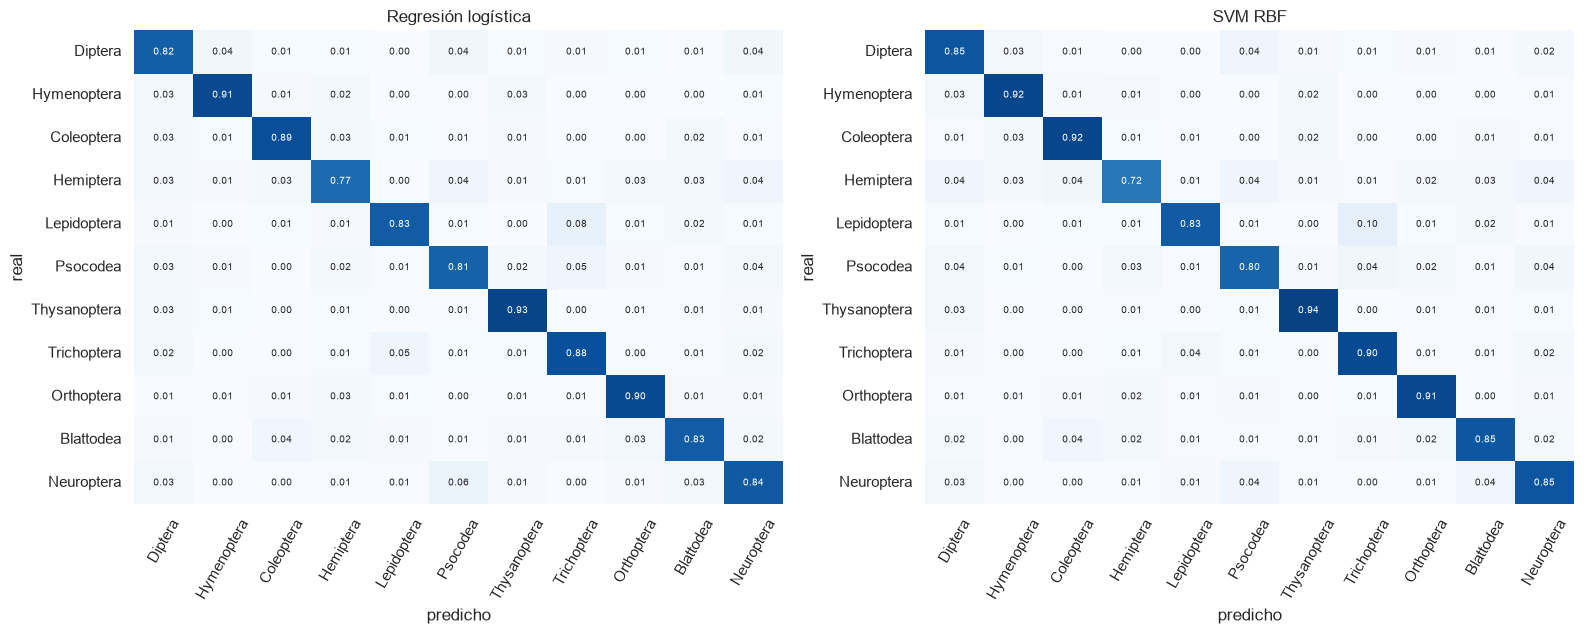

In [ ]:
# Matrices de confusión normalizadas por fila (recall de cada orden)
# Ilustración: Matrices de confusión en test, normalizadas por fila, de la regresión logística y el SVM RBF.
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (nombre, p) in zip(axes, pred.items()):
    cm = confusion_matrix(y_test, p, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False,
                xticklabels=ORDENES, yticklabels=ORDENES, annot_kws={"size": 7})
    ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(nombre)
    ax.tick_params(axis="x", rotation=60); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

,test · familias frecuentes,test · familias raras,acierto frecuentes · Regresión logística,acierto raras · Regresión logística,acierto frecuentes · SVM RBF,acierto raras · SVM RBF
orden,,,,,,
Diptera,127,73,0.850,0.767,0.858,0.849
Hymenoptera,75,121,0.947,0.876,0.960,0.884
Coleoptera,96,104,0.844,0.923,0.865,0.962
Hemiptera,115,70,0.791,0.743,0.757,0.686
Lepidoptera,73,75,0.890,0.760,0.890,0.760
Psocodea,151,33,0.861,0.727,0.848,0.697
Thysanoptera,197,0,0.924,NaN,0.934,NaN
Trichoptera,159,40,0.906,0.750,0.937,0.750
Orthoptera,180,19,0.928,0.632,0.933,0.684


Regresión logística: acierto en familias frecuentes 0.879 frente a raras 0.804 (test exacto de Fisher: odds ratio = 1.77, p = 2.8e-05)
SVM RBF: acierto en familias frecuentes 0.886 frente a raras 0.818 (test exacto de Fisher: odds ratio = 1.72, p = 0.00011)
Regresión logística: correlación de Spearman entre imágenes de la familia en desarrollo y su acierto en test (familias con ≥ 5 en test, n = 72): ρ = 0.13, p = 0.29
SVM RBF: correlación de Spearman entre imágenes de la familia en desarrollo y su acierto en test (familias con ≥ 5 en test, n = 72): ρ = 0.09, p = 0.48


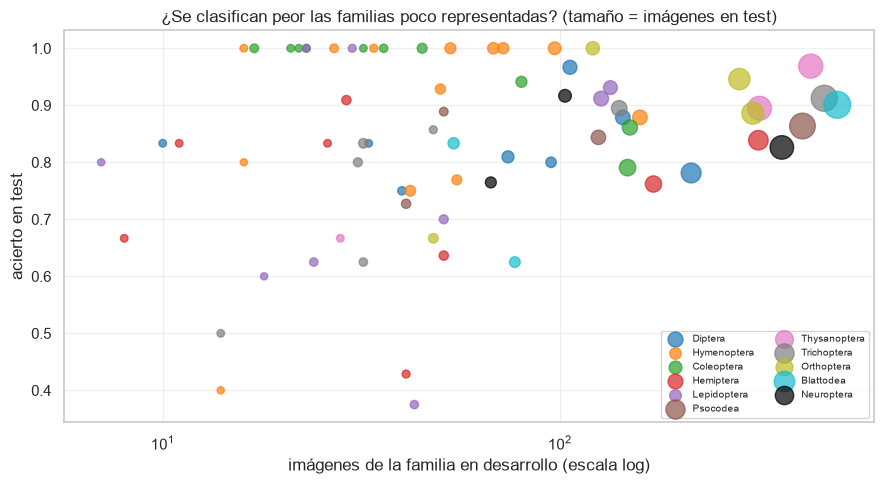

,orden,familia,en desarrollo,en test,acierto · Regresión logística,acierto · SVM RBF
41,Diptera,Cecidomyiidae,214,64,0.781,0.781
43,Diptera,Chironomidae,144,33,0.879,0.909
50,Diptera,Phoridae,106,30,0.967,0.967
54,Diptera,Sciaridae,95,15,0.800,0.933
42,Diptera,Ceratopogonidae,74,21,0.810,0.952
52,Diptera,Psychodidae,40,8,0.750,1.000
44,Diptera,Dolichopodidae,33,6,0.833,1.000
55,Diptera,Sphaeroceridae,14,2,1.000,1.000
45,Diptera,Drosophilidae,10,6,0.833,0.500
46,Diptera,Hybotidae,8,3,0.333,0.333


In [ ]:
# Desbalance (3/3): ¿las familias poco representadas se clasifican peor? Acierto en test por familia y por frecuencia en desarrollo
fam_all = muestra["family"].fillna("not_classified").to_numpy()
fam_dev, fam_test = fam_all[idx_dev], fam_all[idx_test]
ord_dev, ord_test = np.array(ORDENES)[y_dev], np.array(ORDENES)[y_test]
filas = []
for (o, f), g in pd.DataFrame({"orden": ord_test, "familia": fam_test, "i": np.arange(len(y_test))}).groupby(["orden", "familia"]):
    if f == "not_classified":
        continue
    ii = g["i"].to_numpy()
    filas.append({"orden": o, "familia": f, "en desarrollo": int(((ord_dev == o) & (fam_dev == f)).sum()), "en test": len(ii),
                  **{f"acierto · {n}": float((pred[n][ii] == y_test[ii]).mean()) for n in pred}})
por_familia = pd.DataFrame(filas)
por_familia.to_csv(RUN_DIR / "acierto_test_por_familia.csv", index=False)

# Frecuentes frente a raras: dentro de cada orden, las 3 familias con más imágenes de desarrollo frente al resto
top3 = {o: set(por_familia[por_familia["orden"] == o].nlargest(3, "en desarrollo")["familia"]) for o in ORDENES}
es_top = np.array([fam_test[i] in top3[ord_test[i]] for i in range(len(y_test))])
con_fam = fam_test != "not_classified"
filas = []
for o in ORDENES:
    m = ord_test == o
    fila = {"orden": o, "test · familias frecuentes": int((m & es_top).sum()), "test · familias raras": int((m & ~es_top & con_fam).sum())}
    for n in pred:
        ok = pred[n] == y_test
        fila[f"acierto frecuentes · {n}"] = ok[m & es_top].mean() if (m & es_top).any() else np.nan
        fila[f"acierto raras · {n}"] = ok[m & ~es_top & con_fam].mean() if (m & ~es_top & con_fam).any() else np.nan
    filas.append(fila)
frec_raras = pd.DataFrame(filas).set_index("orden")
# Tabla: Acierto en test por orden en las 3 familias más frecuentes frente al resto de familias, para los dos modelos.
display(frec_raras.round(3))
for n in pred:
    ok = pred[n] == y_test
    a_f, a_r = ok[es_top].mean(), ok[~es_top & con_fam].mean()
    tabla2 = [[int((ok & es_top).sum()), int((~ok & es_top).sum())], [int((ok & ~es_top & con_fam).sum()), int((~ok & ~es_top & con_fam).sum())]]
    razon, p_fis = stats.fisher_exact(tabla2)          # exacto: válido aunque alguna celda tenga pocos casos
    print(f"{n}: acierto en familias frecuentes {a_f:.3f} frente a raras {a_r:.3f} (test exacto de Fisher: odds ratio = {razon:.2f}, p = {p_fis:.2g})")
    registrar_metrica(f"familias_frecuentes_vs_raras · {n}", {"acierto_frecuentes": float(a_f), "acierto_raras": float(a_r), "odds_ratio": float(razon), "p_fisher": float(p_fis)})
sub = por_familia[por_familia["en test"] >= 5]
for n in pred:
    rho, p_rho = stats.spearmanr(sub["en desarrollo"], sub[f"acierto · {n}"])
    print(f"{n}: correlación de Spearman entre imágenes de la familia en desarrollo y su acierto en test (familias con ≥ 5 en test, n = {len(sub)}): ρ = {rho:.2f}, p = {p_rho:.2g}")

# Ilustración: Acierto en test de cada familia (≥ 5 imágenes en test) frente a su número de imágenes en desarrollo, regresión logística.
nombre_rl = "Regresión logística"
fig, ax = plt.subplots(figsize=(9, 5))
paleta = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#000000"]   # 11 colores distinguibles (tab10 + negro)
for i, o in enumerate(ORDENES):
    d_ = sub[sub["orden"] == o]
    ax.scatter(d_["en desarrollo"], d_[f"acierto · {nombre_rl}"], s=12 + 3 * d_["en test"], color=paleta[i], alpha=.7, label=o)
ax.set_xscale("log"); ax.set_xlabel("imágenes de la familia en desarrollo (escala log)"); ax.set_ylabel("acierto en test")
ax.set_title("¿Se clasifican peor las familias poco representadas? (tamaño = imágenes en test)")
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
# Tabla: Acierto en test de las familias de Diptera y Hemiptera (los dos órdenes con más errores), ordenadas por frecuencia.
display(por_familia[por_familia["orden"].isin(["Diptera", "Hemiptera"])].sort_values(["orden", "en desarrollo"], ascending=[True, False]).head(30).round(3))

### Errores por familia

**¿Se clasifican peor las familias poco representadas?** Sí, en conjunto. Pero el número de imágenes, por sí solo, no predice el acierto de una familia concreta.

1. **Efecto agregado de unos 7 puntos.** Se comparan las 3 familias más frecuentes de cada orden (en desarrollo) con el resto:

   | Modelo | Familias frecuentes | Familias raras | Test exacto de Fisher |
   |---|---|---|---|
   | Regresión logística | 0.879 | 0.804 | odds ratio = 1.77, p = 2.8·10⁻⁵ |
   | SVM RBF | 0.886 | 0.818 | odds ratio = 1.72, p = 1.1·10⁻⁴ |

2. **Se repite dentro de cada orden.** Con los dos modelos, las frecuentes superan a las raras en 8 de los 10 órdenes que permiten comparar (Thysanoptera no tiene familias raras).
   - **Excepciones:** Coleoptera, con 0.92–0.96 en raras frente a 0.84–0.87 en frecuentes, y Neuroptera, con solo 2 imágenes raras.
   - **Mayores caídas:** Blattodea (0.87 → 0.38–0.50, con solo 8 imágenes raras), Orthoptera (0.93 → 0.63–0.68), y Psocodea, Lepidoptera y Trichoptera (0.85–0.94 → 0.70–0.76).
   - Como el efecto aparece orden por orden, no es un artefacto de mezclar órdenes fáciles y difíciles.
3. **Por familia, la relación es débil y no significativa.** Spearman sobre las 72 familias con al menos 5 imágenes en test da ρ = 0.13 (p = 0.29) con la regresión logística y ρ = 0.09 (p = 0.48) con el SVM.
   - El gráfico explica por qué: tiene forma de embudo. Las familias con 10–50 imágenes de desarrollo tienen pocas imágenes en test (5–15), y su acierto salta entre 0.4 y 1.0 por puro ruido de muestreo.
   - Las familias grandes se agrupan entre 0.76 y 0.97.
4. **La abundancia no garantiza acierto; la morfología pesa:**
   - **Diptera:** Cecidomyiidae, la familia más abundante (214 imágenes de desarrollo), se queda en **0.78** con ambos modelos, por debajo de Phoridae (0.97) y Chironomidae (0.88–0.91). *Hipótesis:* son mosquitos muy pequeños y delicados, que en un recorte de 224 px pierden los rasgos que los distinguen de otros nematóceros.
   - **Hemiptera:** Aleyrodidae (172 imágenes de desarrollo) llega solo a 0.76, Aphididae a 0.43 y Rhyparochromidae a 0.45–0.64. El orden reúne formas muy distintas (chicharritas, moscas blancas, pulgones, chinches), y eso explica su recall bajo (0.72–0.77): no hay un "aspecto de Hemiptera" único.

> **Conclusión:**
> - Los errores se concentran en las familias de la cola de cada orden y en los órdenes morfológicamente heterogéneos. Para mejorar no basta con más imágenes del orden: hay que **cubrir sus familias**.
> - Para un uso en Tiputini, eso implica muestrear por familia (o ponderar por familia) al ampliar el entrenamiento, y enviar a revisión humana las predicciones de baja confianza.
> - **Limitación:** la versión estricta del contraste por orden sería un test de Cochran–Mantel–Haenszel. Aquí, la consistencia en 8 de 10 órdenes cumple ese papel de forma descriptiva.

SVM RBF: 287 errores de 2100 imágenes de test


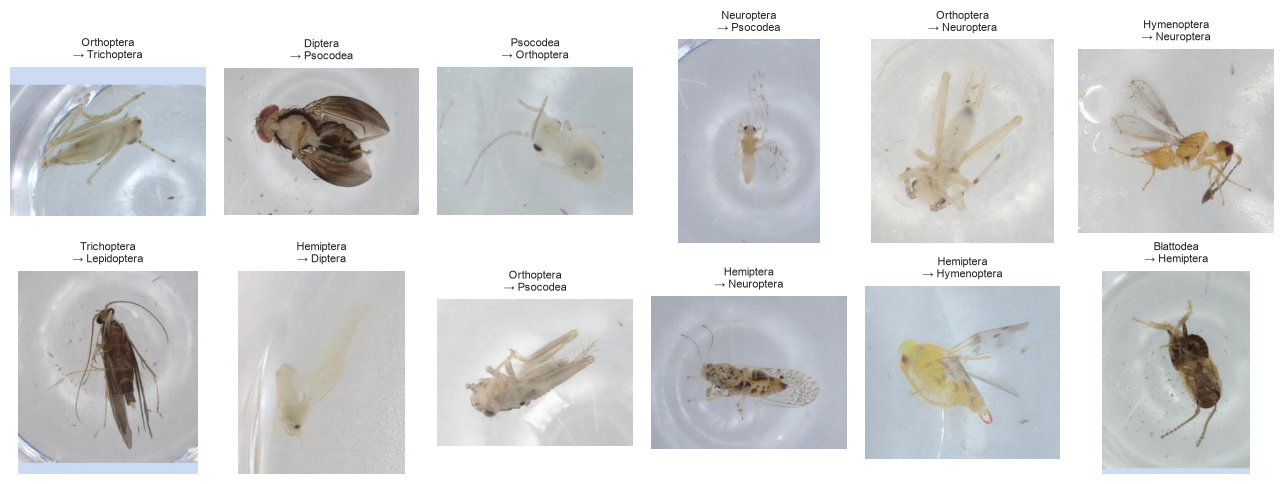

In [ ]:
# Ejemplos mal clasificados por el mejor modelo en test (para entender los errores, no para ajustar nada)
mejor_test = max(pred, key=lambda n: f1_score(y_test, pred[n], average="macro"))
mal = np.where(pred[mejor_test] != y_test)[0]
sel = rng.choice(mal, size=min(12, len(mal)), replace=False) if len(mal) else []
print(f"{mejor_test}: {len(mal)} errores de {len(y_test)} imágenes de test")
if len(sel):
    # Ilustración: Doce imágenes de test mal clasificadas por el mejor modelo (real → predicho).
    fig, axes = plt.subplots(2, 6, figsize=(13, 5))
    with h5py.File(H5_PATH, "r") as f:
        cont = f[GRUPO] if GRUPO else f
        for ax, i in zip(axes.ravel(), sel):
            ax.imshow(leer_imagen(cont, muestra.loc[idx_test[i], "image_file"])); ax.axis("off")
            ax.set_title(f"{ORDENES[y_test[i]]}\n→ {ORDENES[pred[mejor_test][i]]}", fontsize=8)
    for ax in axes.ravel()[len(sel):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

### Resultados en test

| | macro-F1 | accuracy | balanced accuracy |
|---|---|---|---|
| Regresión logística | 0.851 | 0.854 | 0.853 |
| SVM RBF | 0.861 | 0.863 | 0.863 |

**Los resultados en test confirman lo visto en la CV:**
- **Estimación honesta:** el macro-F1 de la regresión logística en test (0.851) coincide con su CV (0.851). El del SVM (0.861) queda algo por encima de su CV (0.855).
- **McNemar:** de las 2 100 imágenes, solo la regresión logística acierta en 51 y solo el SVM en 71; **p = 0.085**. Tampoco es significativo con α = 0.05, coherente con el t-test corregido de la §6.

**Por orden (matrices de confusión):**
1. **Los mejores:** Thysanoptera (F1 0.91–0.92), Hymenoptera (0.91), Orthoptera (0.90) y Coleoptera (0.89–0.90). Son órdenes de forma corporal muy característica: trips alargados y diminutos, avispas con "cintura", saltamontes con patas traseras grandes, escarabajos con élitros.
2. **Los más difíciles:** **Hemiptera** (recall 0.72–0.77), cuyos errores se reparten entre casi todos los órdenes, y **Diptera** (F1 0.81–0.83). Coincide con su baja pureza en el t-SNE: son los órdenes morfológicamente más heterogéneos.
3. **La confusión más sistemática es biológicamente coherente:** el **8–10 % de Lepidoptera se clasifica como Trichoptera**, y el 4–5 % al revés. Polillas y tricópteros son órdenes hermanos (superorden Amphiesmenoptera), con alas cubiertas de escamas o pelos y aspecto muy parecido. El modelo confunde lo que también confunde un observador no experto.
4. **Neuroptera**, con menos ejemplos (676), tiene la menor precisión (0.72–0.76). Recibe errores de Diptera y Psocodea.

**Los ejemplos mal clasificados** (figura anterior) tienen rasgos comunes:
- ejemplares **pálidos o translúcidos** (probablemente inmaduros o recién mudados), con poco contraste contra el fondo del vial;
- insectos **pequeños, dañados o en posturas atípicas**: patas y alas plegadas, de lado;
- individuos atípicos de su orden: un saltamontes inmaduro sin alas desarrolladas, un hemíptero alado que se parece a una avispa.

Son casos difíciles también para un observador no experto.

In [ ]:
# Registro de la ejecución: qué quedó guardado (checkpoints, métricas, resultados) y dónde
log.info("Fin de la ejecución")
archivos = sorted(p for p in RUN_DIR.iterdir() if p.is_file())
# Tabla: Archivos del registro de esta ejecución (checkpoints joblib, métricas, CSV de resultados y bitácora).
display(pd.DataFrame({"archivo": [p.name for p in archivos], "MB": [round(p.stat().st_size / 1e6, 2) for p in archivos]}))
print(f"Carpeta del registro: {RUN_DIR}")
print(f"Datos guardados para reejecutar sin descargar: {MUESTRA_H5.name} · {MUESTRA_CSV.name} · {POBLACION_JSON.name} · {EMB_PATH.name}")
print("\nResumen (metricas.json):\n" + METRICAS.read_text()[:3000])

2026-11-21 00:27:33 | INFO | Fin de la ejecución


,archivo,MB
0,acierto_test_por_familia.csv,0.01
1,comparacion_10x10_por_fold.csv,0.01
2,composicion_familias_muestra.csv,0.00
3,control_calidad_imagenes.csv,0.77
4,curva_aprendizaje.csv,0.00
5,curva_aprendizaje_2678dd7f72.joblib,0.00
6,curva_aprendizaje_rl.csv,0.00
7,curva_aprendizaje_rl_47a773306e.joblib,0.00
8,curva_validacion_rl_860fd527ee.joblib,0.00
9,curva_validacion_svm_6733f2408f.joblib,0.00


Carpeta del registro: /Users/miguelestebanalvarez/datasets/BIOSCAN-1M/registro/v1
Datos guardados para reejecutar sin descargar: muestra_N1000_min500_seed42.h5 · muestra_N1000_min500_seed42.csv · eda_poblacion_bioscan1m.json · embeddings_resnet50_10500_seed42.npz

Resumen (metricas.json):
{
  "muestra": {
    "imagenes": 10500,
    "ordenes": [
      "Diptera",
      "Hymenoptera",
      "Coleoptera",
      "Hemiptera",
      "Lepidoptera",
      "Psocodea",
      "Thysanoptera",
      "Trichoptera",
      "Orthoptera",
      "Blattodea",
      "Neuroptera"
    ],
    "desarrollo": 8400,
    "test": 2100
  },
  "tsne_pureza_media": 0.4296190476190476,
  "regresion_logistica_tuning": {
    "mejores": {
      "clf__C": 0.01,
      "filtro__k": 1024
    },
    "macro_f1_cv": 0.850793875544625,
    "desv": 0.008119185306075069
  },
  "svm_rbf_tuning": {
    "mejores": {
      "clf__C": 10.0,
      "clf__gamma": 9.765625e-05
    },
    "gamma_por_k": 0.1,
    "macro_f1_cv": 0.85329804133314

## §8 · Conclusiones

1. **Una ResNet-50 preentrenada en ImageNet, sin reentrenar, sí sirve para clasificar insectos de trampa Malaise por orden:**
   - macro-F1 ≈ **0.85** en 11 órdenes, frente a ~0.09 del azar;
   - en 5 (regresión logística) o 6 (SVM) de los 11 órdenes, F1 de 0.86 a 0.92;
   - respuesta afirmativa a la pregunta 1, aunque lejos de un uso sin supervisión: ~1 de cada 7 ejemplares se clasificaría mal.
2. **El clasificador no lineal no supera de forma demostrable al lineal.**
   - El SVM RBF obtiene +0.4 puntos de macro-F1 en la CV 10×10 y +1.0 en test, pero el **t-test corregido (p = 0.10) y McNemar (p = 0.085) no permiten rechazar la igualdad** con α = 0.05.
   - Con el criterio del modelo más simple dentro del empate se recomienda la **regresión logística**: 15 veces más rápida, 170 veces más liviana e interpretable.
3. **La prueba estadística elegida cambia la conclusión.** Wilcoxon y el t-test ingenuo daban p ≈ 10⁻⁷ sobre los mismos 100 folds. Ignorar que los folds repetidos comparten datos habría llevado a declarar "significativa" una diferencia que no lo es.
4. **Dónde fallan los modelos:** en los órdenes morfológicamente más diversos (Hemiptera, Diptera) y entre órdenes emparentados (Lepidoptera ↔ Trichoptera). El t-SNE y la pureza de vecinos lo anticipaban: el límite está en la representación, no en el clasificador.
   - Dentro de cada orden, las familias raras se aciertan unos 7 puntos menos que las 3 dominantes (Fisher sobre el total, p < 0.001; la brecha aparece en 8 de 10 órdenes). Que el orden esté balanceado no implica que sus familias lo estén.
5. **Hay varianza, pero no overfitting en el modelo elegido:** la regularización elegida está en el mínimo de la pérdida de validación (curva en U), y el test coincide con la CV. Las curvas de aprendizaje de los dos modelos indican alta varianza: la validación sigue subiendo con más datos. El siguiente paso con más retorno es **usar más imágenes por orden y una representación específica del dominio**:
   - fine-tuning de la red, o un modelo preentrenado con imágenes de biodiversidad, con la GPU H200 de la USFQ, en el curso de Deep Learning;
   - no cambiar de clasificador clásico.
6. **Para Tiputini:** el modelo podría **preclasificar** las muestras y dejar al especialista solo la verificación, priorizando los casos de baja confianza y los órdenes difíciles.

**Limitaciones:**
- **Datos:** BIOSCAN no incluye ejemplares de Tiputini; está dominado por Costa Rica y Canadá, y el TSV no permite filtrar por país.
- **Muestra:** se excluyeron 8 órdenes raros, y se trabajó con una muestra balanceada que no refleja la distribución real de una trampa (79 % Diptera).
- **Preprocesamiento:** el recorte central de 224 px puede cortar apéndices.
- **Validación:** sin nested CV, los hiperparámetros se eligieron con una CV distinta (semilla 42) de la de la comparación (semilla 2026). El test reservado confirma los resultados, pero queda un posible sesgo de selección leve.

## §9 · Referencias (formato IEEE)

[1] Z. Gharaee *et al.*, "A step towards worldwide biodiversity assessment: The BIOSCAN-1M insect dataset," in *Advances in Neural Information Processing Systems 36 (NeurIPS) Datasets and Benchmarks Track*, 2023. arXiv:2307.10455.

[2] BIOSCAN-ML, "BIOSCAN-1M," Hugging Face Datasets, 2023. [Online]. Available: https://huggingface.co/datasets/bioscan-ml/BIOSCAN-1M

[3] D. Steinke *et al.*, "Towards a taxonomy machine: A training set of 5.6 million arthropod images," *Data*, vol. 9, no. 11, art. 122, 2024, doi: 10.3390/data9110122. (Composición geográfica del proyecto BIOSCAN: 62 % Costa Rica.)

[4] K. He, X. Zhang, S. Ren y J. Sun, "Deep residual learning for image recognition," in *Proc. IEEE Conf. Computer Vision and Pattern Recognition (CVPR)*, 2016, pp. 770–778.

[5] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[6] A. Paszke *et al.*, "PyTorch: An imperative style, high-performance deep learning library," in *Advances in Neural Information Processing Systems 32*, 2019.

[7] L. van der Maaten y G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[8] C. Nadeau e Y. Bengio, "Inference for the generalization error," *Machine Learning*, vol. 52, no. 3, pp. 239–281, 2003.

[9] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, 1945.

[10] T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms," *Neural Computation*, vol. 10, no. 7, pp. 1895–1923, 1998.

[11] F. Grijalva, *Aprendizaje Supervisado: presentaciones del curso* (transfer learning, selección de modelos, regularización), Maestría en Inteligencia Artificial, Universidad San Francisco de Quito, 2026.

## Anexo · Uso de IA generativa

Se usó Claude (Anthropic) como asistente. El prompt correspondiente está como comentario al inicio de cada celda de código, como exige la rúbrica. Prompts principales, en orden:

1. *"Para el proyecto quiero hacer algo referente a la tesis del tiputini quizás clasificación de imágenes"*
2. *"BIOSCAN-1M: ¿qué contiene? ¿podemos utilizarlo para cumplir con todas las instrucciones del proyecto?"*
3. *"dame el plan a seguir mapeado con las instrucciones del proyecto, también dime el dataset que vamos a utilizar, si vamos a hacerlo con una muestra del mismo, dame el tema del proyecto"*
4. *"Apruebo todo implementa todo lo necesario y descarga el dataset; si tienes hallazgos inclúyelos en el archivo .md; implementa todo el plan"*
5. *"incluye alguna forma de registro para que se guarde el entrenamiento, checkpoints y también para que no tenga que ejecutar todo el notebook de nuevo guarda el dataset"*
6. *"revisa completamente y evalúa según las indicaciones del proyecto"*
7. *"y analizando los datos, podemos saber si están distribuidos equitativamente o hay más peso en algunas especies de insectos"* (aprobado: *"agrega los 3 puntos"*)
8. *"en el desarrollo existe un pipeline de datos, limpieza, modelo, entrenamiento y test?"* (aprobado: *"de acuerdo agrégalo"*)
9. *"¿se encuentran los gráficos del loss para saber si hubo overfitting?"* y *"estos gráficos están? Es necesario incluirlos porque una de las preguntas va a ser si hubo overfitting"*

El asistente propuso el diseño (dataset, muestra, extractor, modelos, validación y pruebas), escribió el código y redactó los análisis a partir de los resultados reales de la ejecución. El estudiante aprobó cada decisión, ejecutó el notebook y revisó los resultados.